# Milestone 3 : Construire le moteur de consolidation

## Section 0 : Ce que nous construisons

Au milestone 2, nous avons mesuré notre situation : nos livraisons coûtent
**143 422 €** sur le périmètre que nous optimisons, parce que nos camions partent
presque vides. Ici, nous construisons le **moteur** qui corrige cela.

Notre moteur fait trois choses, simplement :

1. pour chaque couple **fournisseur x usine**, il choisit **un profil de livraison
   stable** (le même rythme sur tout l'horizon) ;
2. il **regroupe** les besoins dans des camions bien remplis, à raison d'**un seul
   camion par couple et par jour** (H19) ;
3. il **chiffre l'économie** par rapport à notre baseline.

Trois règles nouvelles encadrent ce milestone :

- **H19** : un fournisseur livre une usine avec **au plus un camion
  par jour** (24 500 kg et 110,4 m³ au plus). **Une ligne n'est jamais coupée.**
- **H20** : une ligne plus lourde qu'un camion est un
  **envoi exceptionnel**, traité à part. Nous l'appliquons **aussi à la situation
  actuelle** pour comparer à règles égales.
- **H21** : le profil peut être suivi plus ou moins strictement. Nous proposons
  **trois versions** du moteur, que nous choisissons avec le paramètre `MODE_PROFIL`,
  pour laisser au client le choix entre **économie** et **régularité**. Un profil proposé est un **engagement** envers le fournisseur : s'il annonce deux passages par semaine, il vient deux fois. Notre **version recommandée par défaut est la version stricte** (`MODE_PROFIL = "strict"`), qui tient le rythme annoncé chaque semaine ; les versions libre et intermédiaire servent de **comparaison**, pour montrer ce que coûterait plus de souplesse. Les trois versions :
  - **libre** : le profil est un **maximum**. Le moteur retient les jours du profil
    qu'il veut, au moins cher ; les lignes d'un jour sauté partent plus tôt (7 jours
    au plus, R1) ;
  - **strict** : **tous** les jours du profil sont retenus, chaque semaine ;
  - **intermédiaire** : au moins **4 semaines respectées** sur l'horizon (toutes si le
    profil en a moins de 4) ; les autres semaines, le moteur fait comme en version libre.

Les trois versions respectent toutes les autres règles : jamais de retard, 7 jours
d'avance au plus, 24 500 kg et 110,4 m³ par camion, un seul couple par camion, un seul
camion par couple et par jour, aucune ligne coupée, l'envoi exceptionnel pour la ligne
trop lourde. **Jamais de camion vide** : un jour sans rien à livrer n'envoie pas de camion.

**Vocabulaire.** Les **jours du profil** sont ses dates de livraison possibles sur
l'horizon (par exemple « lundi, jeudi » sur 7 semaines donne 14 jours). Une semaine est
**respectée** quand tous les jours du profil de cette semaine sont retenus comme jours
de livraison ; un jour retenu sans rien à livrer compte comme respecté, sans camion.

Pour évaluer un profil, nous remplaçons l'affectation simple du milestone 2 par une
**programmation dynamique** (section 4), qui trouve le meilleur choix de jours sous
ces règles. Chaque version du moteur tourne en **moins de 90 secondes** (section
Performance et comparaison des trois versions, avant le bilan).

Nous travaillons sur notre périmètre (lignes `optimise`, H15). Les lignes
`non optimise : info manquante` restent livrées comme aujourd'hui (H16, un camion
plein chacune, **35 032 €** au pire cas) : identiques avant et après, elles ne
changent pas l'économie.

In [1]:
# Nos outils repris du milestone 2, et le precalcul des prix (searchsorted).
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from itertools import combinations
from collections import defaultdict, Counter

CHEMIN_PLANNING = "../data/processed/planning_propre.csv"
CHEMIN_GRILLE = "../data/processed/grille_prix.csv"
CAP_POIDS = 24500.0      # kg par camion (R2)
CAP_VOLUME = 110.4       # m3 par camion (R2)
TRANCHES_KG = [50, 100, 200, 300, 400, 500, 750, 1000, 1500, 2000, 2500, 3000, 3500, 4000]
JOURS = {0: "lundi", 1: "mardi", 2: "mercredi", 3: "jeudi", 4: "vendredi"}

planning = pd.read_csv(CHEMIN_PLANNING, parse_dates=["date", "semaine"])
grille = pd.read_csv(CHEMIN_GRILLE, index_col=0)
grille.columns = grille.columns.astype(str)
grille.index = grille.index.astype(str)

# Notre perimetre : les lignes optimisables (H15). ligne_grille en texte entier.
opt = planning[planning["statut"] == "optimise"].copy()
opt["ligne_grille"] = opt["ligne_grille"].apply(lambda x: str(int(float(x))))

# Precalcul : pour chaque ligne de grille, le tableau de ses 15 prix (14 tranches + ">4000").
# np.searchsorted trouve la tranche en un seul appel : le moteur reste rapide.
BORNES = np.array(TRANCHES_KG, dtype=float)
PRIX_LIGNE = {lg: grille.loc[lg].values.astype(float) for lg in grille.index}

def tranche_poids(kg):
    """Colonne de la grille : la tranche de poids juste au-dessus (au-dela de 4000 -> '>4000')."""
    for t in TRANCHES_KG:
        if kg <= t:
            return str(t)
    return ">4000"

def prix_camion(ligne_grille, poids_kg):
    """Prix d'un camion : case (ligne = distance, colonne = tranche de poids), via searchsorted.
    side='left' reproduit tranche_poids : un poids pile sur une borne reste dans sa tranche."""
    col = int(np.searchsorted(BORNES, poids_kg, side="left"))   # 0..14 (14 = '>4000')
    return float(PRIX_LIGNE[str(ligne_grille)][col])

def prix_exceptionnel(ligne_grille):
    """Prix d'un envoi exceptionnel : tarif '>4000' de la ligne de grille (H20)."""
    return float(PRIX_LIGNE[str(ligne_grille)][-1])

print("Perimetre :", len(opt), "lignes,", opt.groupby(["supplier_id", "plant"]).ngroups, "couples")
print("Baseline du milestone 2 a battre : 143 422,43 EUR")

Perimetre : 4252 lignes, 171 couples
Baseline du milestone 2 a battre : 143 422,43 EUR


## Section 1 : Notre problème, posé clairement

**1. Ce que nous décidons.** Pour chaque couple fournisseur x usine, **un seul
profil de livraison** stable, et, pour ce profil, **quels jours nous utilisons
vraiment**, selon la version choisie (H21).

**2. Ce que nous minimisons (fonction objectif).** Le **coût total de transport**,
somme du prix de chaque camion, lu dans la grille (ligne = distance, colonne = poids) :

$$\text{Coût} = \sum_{\text{couples}} \; \sum_{\text{jours livrés}} \; \text{prix}(\text{ligne\_grille},\ \text{poids du camion})$$

**3. Nos contraintes**, une par ligne :

- **R1** : un besoin est livré le jour même ou **avant**, au plus **7 jours** avant, jamais en retard ;
- **R2** : un camion porte au plus **24 500 kg** et **110,4 m³** ;
- **R3** : un camion ne transporte **qu'un seul couple** fournisseur x usine ;
- **R4** : lissage, les livraisons d'une usine sont **réparties dans la semaine** ;
- **H19** : **au plus un camion par couple et par jour** ; une ligne n'est jamais coupée ;
- **H20** : une ligne plus lourde qu'un camion est un **envoi exceptionnel** (un camion, tarif ">4000") ;
- **H21** : selon la version (`MODE_PROFIL`), le profil est un **maximum** (libre), est suivi **tous
  les jours** (strict), ou doit être **respecté au moins 4 semaines** (intermédiaire) ;
- **jamais de camion vide** : un jour sans rien à livrer n'envoie pas de camion ;
- livraisons du **lundi au vendredi**, **aucune livraison la semaine de Noël** (H7), **pas avant** le premier jour de livraison possible (lundi 02/11, 7 jours avant le premier besoin du 09/11).

**4. Pourquoi regrouper fait gagner.** Deux petits envois dans un seul camion coûtent
moins cher que deux camions séparés : le prix monte moins vite que le poids.
Vérifions-le sur la grille, à 50 km.

In [2]:
# Regrouper deux envois contre les livrer separement, a 50 km.
exemples = [(300, 300), (1000, 1000), (2000, 2000), (10000, 10000)]
lignes = []
for a, b in exemples:
    separe = prix_camion("50", a) + prix_camion("50", b)
    regroupe = prix_camion("50", a + b)   # a+b <= 24500 : tient dans un camion
    lignes.append({"envois (kg)": f"{a} + {b}", "2 camions separes": round(separe, 2),
                   "1 camion regroupe": round(regroupe, 2), "economie (EUR)": round(separe - regroupe, 2),
                   "economie (%)": round((separe - regroupe) / separe * 100, 1)})
gain_regroupement = pd.DataFrame(lignes)
display(gain_regroupement)

,envois (kg),2 camions separes,1 camion regroupe,economie (EUR),economie (%)
0,300 + 300,105.90,84.92,20.99,19.8
1,1000 + 1000,205.16,145.73,59.43,29.0
2,2000 + 2000,291.46,206.83,84.63,29.0
3,10000 + 10000,427.83,213.92,213.92,50.0


**Notre constat :** regrouper gagne toujours, et d'autant plus que les envois
sont gros : **19,8 %** pour 300 + 300 kg, **29 %** vers 1 à 2 t, jusqu'à **50 %**
pour 10 + 10 t. C'est la raison d'être de notre moteur.

In [3]:
# H19 : un seul camion par jour. 26 t ne tiennent pas en un camion le meme jour ;
# elles partent sur deux jours (un plein, un petit), ce qui reste bien moins cher que deux moities.
sep = 2 * prix_camion("50", 13000)                              # 26 t en deux camions egaux
plein = prix_camion("50", CAP_POIDS) + prix_camion("50", 26000 - CAP_POIDS)  # 1 plein + le reste, 2 jours
print("26 t a 50 km :")
print("  2 camions de 13 t                :", round(sep, 2), "EUR")
print("  1 camion plein + 1,5 t (2 jours) :", round(plein, 2), "EUR")
print("  economie du remplissage a fond   :", round(sep - plein, 2), "EUR (", round((sep - plein) / sep * 100, 1), "% )")

26 t a 50 km :
  2 camions de 13 t                : 427.83 EUR
  1 camion plein + 1,5 t (2 jours) : 335.66 EUR
  economie du remplissage a fond   : 92.17 EUR ( 21.5 % )


**Notre constat :** pour 26 t, **un camion plein plus un petit** coûte
**335,66 €** contre **427,83 €** en deux camions à moitié pleins, soit **21,5 %**
de moins. Avec H19, nous ne mettons qu'**un camion par jour** : le reste part un
**autre jour** du profil. La leçon reste la même : **remplir chaque
camion au maximum**.

## Section 2 : Nos paramètres

Toutes nos règles réglables sont ici, en un seul endroit. Pour changer une règle,
nous changeons cette cellule, rien d'autre. En particulier, **`MODE_PROFIL`** choisit
la version du moteur (`"libre"`, `"strict"` ou `"intermediaire"`), et
**`MIN_SEMAINES_RESPECTEES`** fixe l'objectif de la version intermédiaire. Les sorties
du notebook sont celles de la version choisie.

In [4]:
AVANCE_MAX = 7                      # R1 : au plus 7 jours d'avance, jamais de retard
# Premier jour de livraison possible. La regle des 7 jours d'avance vaut aussi au debut de l'horizon :
# un besoin du lundi 09/11 peut partir des le lundi 02/11. Le calendrier commence donc le 02/11.
PREMIER_JOUR_LIVRAISON = "2026-11-02"
SEMAINES_FERMEES = ["2026-12-21"]   # H7 : lundi des semaines sans livraison (Noel)
TOLERANCE_LISSAGE = 0.02            # H17 : pour lisser, on accepte +2 % de cout au plus
UN_CAMION_PAR_JOUR = True           # H19 : au plus un camion par couple et par jour
# H21 : version recommandee par defaut. Un profil propose est un engagement envers le fournisseur :
# le rythme annonce est tenu chaque semaine (version stricte). "libre" et "intermediaire" servent de comparaison.
MODE_PROFIL = "strict"              # "libre", "strict" ou "intermediaire"
MIN_SEMAINES_RESPECTEES = 4         # H21 : semaines respectees au minimum en version "intermediaire"
TEMPS_MAX_SECONDES = 90             # budget de temps du moteur complet (par version)

MODES = ("libre", "intermediaire", "strict")
assert MODE_PROFIL in MODES, "MODE_PROFIL doit valoir 'libre', 'strict' ou 'intermediaire'."

parametres = pd.DataFrame({
    "parametre": ["AVANCE_MAX (R1)", "PREMIER_JOUR_LIVRAISON", "SEMAINES_FERMEES (H7)", "TOLERANCE_LISSAGE (H17)",
                  "CAP_POIDS (R2)", "CAP_VOLUME (R2)", "UN_CAMION_PAR_JOUR (H19)",
                  "MODE_PROFIL (H21)", "MIN_SEMAINES_RESPECTEES (H21)", "TEMPS_MAX_SECONDES"],
    "valeur": [f"{AVANCE_MAX} jours", PREMIER_JOUR_LIVRAISON, ", ".join(SEMAINES_FERMEES), f"{TOLERANCE_LISSAGE:.0%}",
               f"{CAP_POIDS:.0f} kg", f"{CAP_VOLUME} m3", str(UN_CAMION_PAR_JOUR),
               MODE_PROFIL, f"{MIN_SEMAINES_RESPECTEES} semaines", f"{TEMPS_MAX_SECONDES} s"],
})
display(parametres)

,parametre,valeur
0,AVANCE_MAX (R1),7 jours
1,PREMIER_JOUR_LIVRAISON,2026-11-02
2,SEMAINES_FERMEES (H7),2026-12-21
3,TOLERANCE_LISSAGE (H17),2%
4,CAP_POIDS (R2),24500 kg
5,CAP_VOLUME (R2),110.4 m3
6,UN_CAMION_PAR_JOUR (H19),True
7,MODE_PROFIL (H21),strict
8,MIN_SEMAINES_RESPECTEES (H21),4 semaines
9,TEMPS_MAX_SECONDES,90 s


## Section 3 : Nos profils de livraison (élargis, H18)

Un **profil** décrit un rythme de livraison stable : une **période** (toutes les 1 à
4 semaines), une **phase** (quelle semaine du cycle), et des **jours** de livraison
(lundi à vendredi). Il se répète à l'identique sur l'horizon.

Nous ne nous limitons pas aux profils du PDF (1, 2, 3, 5 fois par semaine) : nous
testons aussi *une semaine sur deux* et au-delà (**H18**). Selon la version (H21), le
moteur utilise tous ces jours (strict) ou peut en sauter (libre, intermédiaire). C'est
la règle des 7 jours (R1) qui décide si un profil est possible pour un couple.

In [5]:
def libelle_profil(p):
    """Libelle lisible d'un profil (ex. '2 / semaine : lundi, jeudi')."""
    noms = ", ".join(JOURS[j] for j in sorted(p["jours"]))
    if p["periode"] == 1:
        return f"{len(p['jours'])} / semaine : {noms}"
    return f"1 semaine sur {p['periode']} (semaine {p['phase'] + 1}) : {noms}"

def sous_ensembles(jours, tailles):
    """Toutes les combinaisons de jours des tailles demandees."""
    return [frozenset(c) for k in tailles for c in combinations(jours, k)]

def generer_profils():
    """Construit la liste des profils candidats (periodes 1 a 4, H18)."""
    profils = []
    for d in sous_ensembles([0, 1, 2, 3, 4], range(1, 6)):          # periode 1 : 31 profils
        profils.append({"periode": 1, "phase": 0, "jours": d})
    for periode in (2, 3, 4):                                        # periodes 2,3,4 : 1 ou 2 jours
        for phase in range(periode):
            for d in sous_ensembles([0, 1, 2, 3, 4], [1, 2]):
                profils.append({"periode": periode, "phase": phase, "jours": d})
    for p in profils:
        p["libelle"] = libelle_profil(p)
        p["type"] = "PDF" if (p["periode"] == 1 and len(p["jours"]) in (1, 2, 3, 5)) else "elargi"
    return profils

PROFILS = generer_profils()
nb_pdf = sum(p["type"] == "PDF" for p in PROFILS)
print("Profils candidats :", len(PROFILS), "| du PDF :", nb_pdf, "| elargis :", len(PROFILS) - nb_pdf)

Profils candidats : 166 | du PDF : 26 | elargis : 140


Ensuite nous posons le **calendrier** des jours de livraison possibles : les jours
ouvrés (lundi à vendredi) du premier jour de livraison possible (lundi 02/11, 7 jours avant le premier besoin) au dernier besoin, sans la semaine fermée. Pour
chaque profil, nous listons une fois pour toutes ses **dates de livraison**.

In [6]:
premier_besoin = opt["date"].min()
d0 = pd.Timestamp(PREMIER_JOUR_LIVRAISON)   # premier jour de livraison possible, 7 jours avant le premier besoin
d1 = opt["date"].max()
# Verification : le premier jour de livraison est bien le premier besoin moins 7 jours, et c'est un jour ouvre.
assert d0 == premier_besoin - pd.Timedelta(AVANCE_MAX, unit="D"), (
    f"PREMIER_JOUR_LIVRAISON ({d0.date()}) doit etre le premier besoin ({premier_besoin.date()}) moins {AVANCE_MAX} jours.")
assert d0.weekday() < 5, "PREMIER_JOUR_LIVRAISON doit etre un jour ouvre (lundi a vendredi)."
lundi0 = d0 - pd.Timedelta(int(d0.weekday()), unit="D")   # lundi de la premiere semaine du calendrier
fermees = set(pd.to_datetime(SEMAINES_FERMEES))

def semaine_fermee(dt):
    """Vrai si la date tombe dans une semaine fermee (H7)."""
    return (dt - pd.Timedelta(int(dt.weekday()), unit="D")) in fermees

jours_ouvres = pd.DatetimeIndex([d for d in pd.date_range(d0, d1, freq="D")
                                 if d.weekday() < 5 and not semaine_fermee(d)])

def dates_profil(p):
    """Les dates de livraison d'un profil sur l'horizon (semaine du cycle modulo la periode)."""
    out = []
    for d in jours_ouvres:
        if d.weekday() in p["jours"]:
            semaine = ((d - pd.Timedelta(int(d.weekday()), unit="D")) - lundi0).days // 7
            if semaine % p["periode"] == p["phase"]:
                out.append(d)
    return np.array(out, dtype="datetime64[D]")

DATES_PROFIL = [dates_profil(p) for p in PROFILS]
print("Jours ouvres de l'horizon :", len(jours_ouvres), "du", d0.date(), "au", d1.date())

Jours ouvres de l'horizon : 35 du 2026-11-02 au 2026-12-18


**Notre constat :** nous obtenons **166 profils candidats** (26 du PDF, 140
élargis) et **35 jours ouvrés** sur l'horizon de livraison (**7 semaines**). Les
livraisons peuvent partir dès le **lundi 02/11**, soit 7 jours avant le premier besoin
du 09/11, jusqu'au 18/12 ; la semaine de Noël n'est pas dans l'horizon. Les besoins, eux,
vont toujours du 09/11 au 18/12. Tout est prêt pour l'évaluation.

## Section 4 : Comment nous évaluons un profil pour un couple (programmation dynamique)

C'est le cœur du calcul. Un profil donne des **jours possibles**. Nous choisissons
**quels jours retenir**, selon la version :

| version | jours retenus |
|---|---|
| libre | ceux que le moteur veut, au moins cher |
| strict | tous les jours du profil, chaque semaine |
| intermédiaire | au moins 4 semaines respectées (toutes si le profil en a moins de 4) ; les autres semaines, ceux que le moteur veut |

Dans les trois versions, chaque ligne part au **dernier jour retenu avant ou égal à son
besoin** ; une livraison le jour *d* porte donc tous les besoins entre *d* et le jour
retenu suivant. Un jour retenu sans besoin n'envoie pas de camion.

**Un petit schéma.** Jours du profil : lun — mar — (lun) — mar. Si nous retenons
seulement les jours marqués d'une croix, chaque besoin « glisse » vers la gauche
jusqu'au jour retenu le plus proche :

```
profil      :  L    M    L    M
retenus     :  X    .    .    X
besoins     : b1   b2   b3   b4
partent le  :  L    L    L    M      (b2, b3 avances sur le lundi retenu, <= 7 jours)
```

**Le calcul de la version libre**, en quatre temps :

1. **Mettre à part les envois exceptionnels** (H20) : une ligne plus lourde qu'un
   camion part seule, tarif ">4000", le jour du profil le plus proche avant ou égal
   à son besoin (7 jours au plus). Elle ne compte ni dans « un camion par jour », ni
   dans le nombre de livraisons.
2. **Préparer une fois** le poids et le volume par date de besoin (tableaux numpy,
   sommes cumulées).
3. **Programmation dynamique.** `meilleur_cout[j]` = coût minimal pour livrer tous
   les besoins **jusqu'à la veille du jour j**, sachant que le jour *j* est retenu.
   Le passage d'un jour retenu *i* au jour retenu suivant *j* (ou à la fin) est
   possible **seulement si** :
   - tous les besoins entre *i* et *j* sont **au plus 7 jours** après *i* (R1) ;
   - leur **poids** total ≤ 24 500 kg et leur **volume** total ≤ 110,4 m³ (H19) ;
   - aucun besoin ne tombe avant le premier jour retenu.

   Coût du passage = `prix_camion(ligne_grille, poids total)` (0 s'il n'y a aucun
   besoin : pas de camion). Grâce à R1, dès qu'un besoin dépasse les 7 jours nous
   arrêtons : seuls les jours suivants proches sont explorés, le calcul est court.
4. **Retrouver le meilleur choix** en remontant les décisions.

Ce résultat est le **meilleur possible** pour la règle « chaque ligne part au dernier
jour retenu avant son besoin » : la programmation dynamique est **exacte** pour ce
problème.

**La version strict** n'a rien à choisir : tous les jours du profil sont retenus, chaque
ligne part au jour du profil le plus proche avant ou égal à son besoin. Si ce jour
dépasse un camion ou s'il est à plus de 7 jours, le profil est impossible.

**La version intermédiaire** reprend la même programmation dynamique, avec un état un
peu plus riche (détails juste après le code de la version libre).

In [7]:
# Nous preparons chaque couple : besoins normaux tries par date, et lignes exceptionnelles a part (H20).
COUPLES = {}
for (s, pl), g in opt.groupby(["supplier_id", "plant"]):
    g = g.sort_values("date")
    exc = (g["weight"].values > CAP_POIDS) | (g["volume"].values > CAP_VOLUME)
    normal = g[~exc]; excep = g[exc]
    COUPLES[(s, pl)] = {
        "besoins": normal["date"].values.astype("datetime64[D]"),
        "poids": normal["weight"].values.astype(float),
        "volume": normal["volume"].values.astype(float),
        "mat": normal["material"].values, "up": normal["unloading_point"].values,
        "qte": normal["schedule_quantity"].values.astype(float),
        "ligne": g["ligne_grille"].iloc[0], "distance": g["distance"].iloc[0],
        "exc_dates": excep["date"].values.astype("datetime64[D]"),
        "exc_poids": excep["weight"].values.astype(float),
        "exc_vol": excep["volume"].values.astype(float), "exc_mat": excep["material"].values,
        "exc_up": excep["unloading_point"].values, "exc_qte": excep["schedule_quantity"].values.astype(float),
        "df": g}

# Couples dont un meme jour de besoin depasse un camion : la DP ne s'applique pas (voir ci-dessous).
jour_sum = opt.groupby(["supplier_id", "plant", "date"]).agg(w=("weight", "sum"), v=("volume", "sum")).reset_index()
jours_lourds = jour_sum[(jour_sum.w > CAP_POIDS) | (jour_sum.v > CAP_VOLUME)]
COUPLES_CAP = set(zip(jours_lourds.supplier_id, jours_lourds.plant))

def cout_exceptionnels(couple, dates):
    """Cout et nombre des envois exceptionnels d'un couple pour un profil ; None si un sans jour (R1)."""
    cout = 0.0; nb = 0
    for bd in couple["exc_dates"]:
        pos = int(np.searchsorted(dates, bd, side="right")) - 1
        if pos < 0:
            return None
        if int((bd - dates[pos]).astype("timedelta64[D]").astype(int)) > AVANCE_MAX:
            return None
        cout += prix_exceptionnel(couple["ligne"]); nb += 1
    return cout, nb

def evaluer_dp(couple, idx_profil):
    """Programmation dynamique : meilleur cout pour 'chaque ligne part au dernier jour retenu <= son besoin'."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    ce = cout_exceptionnels(couple, dates)
    if ce is None:
        return None
    cout_exc, nb_exc = ce
    besoins = couple["besoins"]; poids = couple["poids"]; volume = couple["volume"]; ligne = couple["ligne"]
    if len(besoins) == 0:
        return {"cout": cout_exc, "camions": nb_exc, "livraisons": 0,
                "jours": np.array([], dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}
    ordre = np.argsort(besoins); poids = poids[ordre]; volume = volume[ordre]
    bjours = besoins[ordre].astype("datetime64[D]").astype(int)
    djours = dates.astype("datetime64[D]").astype(int)
    m = len(dates); INF = float("inf")
    cout = [INF] * m; prev = [-1] * m
    for j in range(m):                                   # premier jour retenu valable : aucun besoin avant lui
        if int(np.searchsorted(bjours, djours[j], side="left")) == 0:
            cout[j] = 0.0; prev[j] = -1
        else:
            break
    for i in range(m):
        if cout[i] == INF:
            continue
        k = int(np.searchsorted(bjours, djours[i], side="left"))   # premier besoin >= dates[i]
        cw = 0.0; cv = 0.0; maxneed = -1
        for j in range(i + 1, m):
            while k < len(bjours) and bjours[k] < djours[j]:        # besoins dans [dates[i], dates[j])
                cw += poids[k]; cv += volume[k]; maxneed = bjours[k]; k += 1
            if maxneed >= 0:
                if maxneed - djours[i] > AVANCE_MAX:               # R1 : un besoin trop ancien -> stop
                    break
                if cw > CAP_POIDS + 1e-6 or cv > CAP_VOLUME + 1e-6:  # capacite (H19)
                    break
            c = prix_camion(ligne, cw) if cw > 1e-9 else 0.0
            if cout[i] + c < cout[j]:
                cout[j] = cout[i] + c; prev[j] = i
    best = INF; best_i = -1                               # fin : le camion sur i porte les besoins >= dates[i]
    for i in range(m):
        if cout[i] == INF:
            continue
        lo = int(np.searchsorted(bjours, djours[i], side="left"))
        if lo < len(bjours):
            if bjours[-1] - djours[i] > AVANCE_MAX:
                continue
            cw = float(poids[lo:].sum()); cv = float(volume[lo:].sum())
            if cw > CAP_POIDS + 1e-6 or cv > CAP_VOLUME + 1e-6:
                continue
            c = prix_camion(ligne, cw)
        else:
            c = 0.0
        if cout[i] + c < best:
            best = cout[i] + c; best_i = i
    if best == INF:
        return None
    retenus = []; i = best_i
    while i >= 0:
        retenus.append(i); i = prev[i]
    retenus = sorted(retenus)
    jours_liv = []
    for a in range(len(retenus)):
        lo = int(np.searchsorted(bjours, djours[retenus[a]], side="left"))
        dj = djours[retenus[a + 1]] if a + 1 < len(retenus) else 10**9
        hi = int(np.searchsorted(bjours, dj, side="left"))
        if hi > lo:                                       # jour non vide = une vraie livraison
            jours_liv.append(dates[retenus[a]])
    return {"cout": best + cout_exc, "camions": len(jours_liv) + nb_exc, "livraisons": len(jours_liv),
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}

print("Programmation dynamique prete. Couples a affectation capacite (jour trop lourd) :", sorted(COUPLES_CAP))
print("Jours de besoin plus lourds qu'un camion :", len(jours_lourds))

Programmation dynamique prete. Couples a affectation capacite (jour trop lourd) : [('SUP_00037', 'PLT_002'), ('SUP_00046', 'PLT_004'), ('SUP_00074', 'PLT_003')]
Jours de besoin plus lourds qu'un camion : 5


### La version intermédiaire : la même programmation dynamique, avec un état plus riche

Nous ajoutons deux informations dans l'**état** : le **nombre de semaines respectées
jusqu'ici** (plafonné à l'objectif) et si la **semaine en cours est encore respectée**.
L'état devient (jour retenu *j*, semaines respectées avant la semaine de *j*, semaine de
*j* encore respectée ou non). Pour un passage d'un jour retenu *i* au jour retenu suivant *j* :

- **même semaine** : la semaine reste respectée seulement si aucun jour du profil n'est
  sauté entre *i* et *j* ;
- **semaine suivante ou plus loin** : la semaine de *i* se ferme ; elle compte comme
  respectée si elle l'était encore et si *i* est son dernier jour du profil. Les semaines
  entièrement sautées entre *i* et *j* ne sont pas respectées.

Au départ, les jours avant le premier jour retenu sont sautés ; à la fin, les jours après
le dernier jour retenu aussi. Nous ne gardons que les fins qui **atteignent l'objectif** :
`MIN_SEMAINES_RESPECTEES`, ou **toutes** les semaines du profil s'il en a moins (par
exemple, un profil « 1 semaine sur 3 » n'a que 3 semaines sur l'horizon, voir le contrôle
de la méthode plus bas). Un passage sans besoin coûte 0 : retenir un jour sans rien à
livrer est gratuit et compte comme respecté. Le nombre de semaines est plafonné à
l'objectif : l'état reste petit, et le résultat est **exact** (le moins cher parmi toutes
les façons de livrer qui respectent la règle).

**Un raccourci, exact lui aussi.** Nous lançons d'abord la version libre. Si sa solution
atteint déjà l'objectif, elle est aussi la meilleure de la version intermédiaire (qui ne
peut pas coûter moins que la libre) : nous la gardons sans relancer le calcul.

**Lire les semaines respectées sur une solution.** Pour contrôler une solution (section 8)
et pour comparer les versions, nous relisons les semaines sur les livraisons : un jour du
profil compte comme retenu s'il est livré, ou si aucune ligne ne le « saute » (aucune ligne
livrée avant lui alors que son besoin tombe ce jour-là ou après) ; il n'y avait alors rien
à y livrer.

In [8]:
# Version "intermediaire" : les semaines du profil, le comptage des semaines respectees, et la DP elargie.
def semaines_du_profil(dates):
    """Pour chaque date du profil : le numero de sa semaine (0, 1, 2...) parmi les semaines du profil."""
    if len(dates) == 0:
        return np.array([], dtype=int)
    j = dates.astype("datetime64[D]").astype(int)
    lundis = j - ((j + 3) % 7)                 # le 01/01/1970 est un jeudi : (j + 3) % 7 = 0 le lundi
    return np.unique(lundis, return_inverse=True)[1]

SEM_PROFIL = [semaines_du_profil(d) for d in DATES_PROFIL]

def objectif_semaines(idx_profil):
    """(semaines a respecter, semaines du profil) : MIN_SEMAINES_RESPECTEES, ou toutes s'il y en a moins."""
    nb = int(SEM_PROFIL[idx_profil].max()) + 1 if len(SEM_PROFIL[idx_profil]) else 0
    return min(MIN_SEMAINES_RESPECTEES, nb), nb

def semaines_ok(idx_profil, liv, besoin):
    """Pour chaque semaine du profil : vrai si elle est respectee, lu sur les livraisons. liv et besoin donnent,
    pour chaque ligne normale, son jour de livraison et son jour de besoin. Un jour du profil compte comme retenu
    s'il est livre, ou si aucune ligne ne le saute (livree avant lui alors que son besoin tombe ce jour-la ou
    apres) : il n'y avait alors rien a y livrer. Une semaine est respectee si tous ses jours du profil sont retenus."""
    dates = DATES_PROFIL[idx_profil].astype("datetime64[D]").astype(int); sem = SEM_PROFIL[idx_profil]
    if len(dates) == 0:
        return np.array([], dtype=bool)
    liv = np.asarray(liv, dtype=int); besoin = np.asarray(besoin, dtype=int)
    livre = np.isin(dates, liv)
    if len(liv):
        saute = ((liv[:, None] < dates[None, :]) & (besoin[:, None] >= dates[None, :])).any(axis=0)
    else:
        saute = np.zeros(len(dates), dtype=bool)
    retenu = livre | ~saute
    jours_manques = np.bincount(sem, weights=(~retenu).astype(float), minlength=int(sem.max()) + 1)
    return jours_manques == 0

def semaines_respectees(idx_profil, liv, besoin):
    """(semaines respectees, semaines du profil)."""
    ok = semaines_ok(idx_profil, liv, besoin)
    return int(ok.sum()), len(ok)

def lignes_dp(couple, jours):
    """Pour une solution de la DP : jour de livraison (dernier jour livre <= besoin) et jour de besoin de chaque ligne."""
    bj = couple["besoins"].astype("datetime64[D]").astype(int)
    jj = np.sort(np.asarray(jours).astype("datetime64[D]").astype(int))
    if len(bj) == 0:
        return bj, bj
    return jj[np.searchsorted(jj, bj, side="right") - 1], bj

def evaluer_dp_inter(couple, idx_profil):
    """DP de la version 'intermediaire'. Etat = (jour retenu, semaines respectees jusqu'ici plafonnees a
    l'objectif, semaine en cours encore respectee ou non). Seules les fins qui atteignent l'objectif comptent."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    ce = cout_exceptionnels(couple, dates)
    if ce is None:
        return None
    cout_exc, nb_exc = ce
    besoins = couple["besoins"]; poids = couple["poids"]; volume = couple["volume"]; ligne = couple["ligne"]
    if len(besoins) == 0:
        return {"cout": cout_exc, "camions": nb_exc, "livraisons": 0,
                "jours": np.array([], dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}
    K = objectif_semaines(idx_profil)[0]
    sem = SEM_PROFIL[idx_profil]; m = len(dates)
    premier = np.r_[True, sem[1:] != sem[:-1]]          # premier jour du profil dans sa semaine
    dernier = np.r_[sem[1:] != sem[:-1], True]          # dernier jour du profil dans sa semaine
    ordre = np.argsort(besoins); poids = poids[ordre]; volume = volume[ordre]
    bjours = besoins[ordre].astype("datetime64[D]").astype(int)
    djours = dates.astype("datetime64[D]").astype(int)
    NS = 2 * (K + 1)                                     # etat s = 2 x semaines respectees + semaine en cours ok
    INF = float("inf")
    cout = [[INF] * NS for _ in range(m)]; prev = [[None] * NS for _ in range(m)]
    for j in range(m):                                   # premier jour retenu : les jours avant lui sont sautes
        if int(np.searchsorted(bjours, djours[j], side="left")) == 0:
            cout[j][1 if premier[j] else 0] = 0.0
        else:
            break
    for i in range(m):
        etats = [(s, cout[i][s]) for s in range(NS) if cout[i][s] < INF]
        if not etats:
            continue
        k = int(np.searchsorted(bjours, djours[i], side="left"))
        cw = 0.0; cv = 0.0; maxneed = -1
        for j in range(i + 1, m):
            while k < len(bjours) and bjours[k] < djours[j]:
                cw += poids[k]; cv += volume[k]; maxneed = bjours[k]; k += 1
            if maxneed >= 0:
                if maxneed - djours[i] > AVANCE_MAX:               # R1
                    break
                if cw > CAP_POIDS + 1e-6 or cv > CAP_VOLUME + 1e-6:  # capacite (H19)
                    break
            c = prix_camion(ligne, cw) if cw > 1e-9 else 0.0
            for s, val in etats:
                nbs, en_cours = divmod(s, 2)
                if sem[j] == sem[i]:                     # meme semaine : un jour saute entre i et j la casse
                    s2 = 2 * nbs + (en_cours if j == i + 1 else 0)
                else:                                    # la semaine de i se ferme ; les semaines entre i et j sont sautees
                    fermee_ok = 1 if (en_cours and dernier[i]) else 0
                    s2 = 2 * min(K, nbs + fermee_ok) + (1 if premier[j] else 0)
                if val + c < cout[j][s2]:
                    cout[j][s2] = val + c; prev[j][s2] = (i, s)
    best = INF; best_etat = None                         # fin : le camion sur i porte les besoins >= dates[i]
    for i in range(m):
        lo = int(np.searchsorted(bjours, djours[i], side="left"))
        if lo < len(bjours):
            if bjours[-1] - djours[i] > AVANCE_MAX:
                continue
            cw = float(poids[lo:].sum()); cv = float(volume[lo:].sum())
            if cw > CAP_POIDS + 1e-6 or cv > CAP_VOLUME + 1e-6:
                continue
            c = prix_camion(ligne, cw)
        else:
            c = 0.0
        for s in range(NS):
            if cout[i][s] == INF:
                continue
            nbs, en_cours = divmod(s, 2)
            if min(K, nbs + (1 if (en_cours and dernier[i]) else 0)) < K:   # objectif non atteint
                continue
            if cout[i][s] + c < best:
                best = cout[i][s] + c; best_etat = (i, s)
    if best == INF:
        return None
    retenus = []; e = best_etat
    while e is not None:
        retenus.append(e[0]); e = prev[e[0]][e[1]]
    retenus = sorted(retenus)
    jours_liv = []
    for a in range(len(retenus)):
        lo = int(np.searchsorted(bjours, djours[retenus[a]], side="left"))
        dj = djours[retenus[a + 1]] if a + 1 < len(retenus) else 10**9
        hi = int(np.searchsorted(bjours, dj, side="left"))
        if hi > lo:                                      # jour retenu non vide = une vraie livraison
            jours_liv.append(dates[retenus[a]])
    return {"cout": best + cout_exc, "camions": len(jours_liv) + nb_exc, "livraisons": len(jours_liv),
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}

print("Version intermediaire prete. Objectif : au moins", MIN_SEMAINES_RESPECTEES,
      "semaines respectees (ou toutes si le profil en a moins).")

Version intermediaire prete. Objectif : au moins 4 semaines respectees (ou toutes si le profil en a moins).


**Cas particulier : un jour trop lourd.** Si un **même jour de besoin** dépasse
un camion, la règle « une livraison par jour » ne peut pas le porter et la
programmation dynamique ne trouve pas de solution. Cela arrive sur **5 jours**, chez
**3 couples** (SUP_00046 x PLT_004, SUP_00037 x PLT_002, SUP_00074 x PLT_003).

Pour ces 3 couples, nous utilisons une **méthode approchée**, en deux temps :

1. **Placement des lignes une par une** (règle gloutonne), sur **tous les jours du
   profil** : par date de besoin croissante et les plus lourdes d'abord, chaque ligne va
   au **jour du profil le plus tardif avant ou égal** à son besoin (7 jours au plus)
   **où il reste de la place en poids ET en volume**. Si une ligne ne trouve aucune
   place, le profil est **impossible**. C'est le résultat de la version **strict**.
2. En versions **libre** et **intermédiaire**, nous essayons ensuite de **ne plus livrer
   un jour** : si toutes ses lignes tiennent sur un jour livré précédent (7 jours au plus,
   capacité respectée) et si le coût baisse, nous les y déplaçons. En version
   intermédiaire, nous refusons tout déplacement qui ferait passer sous l'objectif de
   semaines respectées. À chaque tour, nous gardons le déplacement qui fait le plus
   baisser le coût, et **nous recommençons tant que le coût baisse**.

Cette méthode est **approchée** : pour ces 3 couples seulement, nous ne sommes pas sûrs
d'avoir trouvé le moins cher possible. Tous les autres couples sont traités de façon exacte.

Enfin, un réglage : si **UN_CAMION_PAR_JOUR** est faux, on garde l'ancien comportement à
**plusieurs camions** par jour (H13), sur tous les jours du profil, quelle que soit la version.

In [9]:
def evaluer_cap(couple, idx_profil):
    """Affectation avec capacite (glouton) pour un couple dont un jour depasse un camion :
    chaque ligne au jour du profil le plus tardif <= son besoin ou il reste de la place (tous les jours du profil)."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    ce = cout_exceptionnels(couple, dates)
    if ce is None:
        return None
    cout_exc, nb_exc = ce
    besoins = couple["besoins"]; poids = couple["poids"]; volume = couple["volume"]
    if len(besoins) == 0:
        return {"cout": cout_exc, "camions": nb_exc, "livraisons": 0, "affect": {},
                "jours": np.array([], dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}
    djours = dates.astype("datetime64[D]").astype(int)
    bjours = besoins.astype("datetime64[D]").astype(int)
    ordre = sorted(range(len(besoins)), key=lambda i: (bjours[i], -poids[i]))   # date croissante, plus lourd d'abord
    charge_p = defaultdict(float); charge_v = defaultdict(float); affect = defaultdict(list)
    for i in ordre:
        cand = [k for k in range(len(dates)) if djours[k] <= bjours[i] and bjours[i] - djours[k] <= AVANCE_MAX]
        cand.sort(key=lambda k: -djours[k])                 # jour le plus tardif d'abord
        place = False
        for k in cand:
            if charge_p[k] + poids[i] <= CAP_POIDS + 1e-6 and charge_v[k] + volume[i] <= CAP_VOLUME + 1e-6:
                charge_p[k] += poids[i]; charge_v[k] += volume[i]; affect[k].append(i); place = True; break
        if not place:
            return None
    return resultat_cap(couple, idx_profil, dict(affect), cout_exc, nb_exc)

def resultat_cap(couple, idx_profil, affect, cout_exc, nb_exc):
    """Resultat d'une affectation ligne -> jour : un camion par jour qui porte au moins une ligne."""
    dates = DATES_PROFIL[idx_profil]; cout = 0.0; jours_liv = []
    for k in sorted(affect):
        if affect[k]:
            cout += prix_camion(couple["ligne"], couple["poids"][affect[k]].sum()); jours_liv.append(dates[k])
    return {"cout": cout + cout_exc, "camions": len(jours_liv) + nb_exc, "livraisons": len(jours_liv),
            "affect": {k: v for k, v in affect.items() if v},
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}

def respectees_cap(couple, idx_profil, affect):
    """Semaines respectees d'une affectation ligne -> jour (meme regle que la validation)."""
    dj = DATES_PROFIL[idx_profil].astype("datetime64[D]").astype(int)
    bj = couple["besoins"].astype("datetime64[D]").astype(int)
    liv = [dj[k] for k, v in affect.items() for i in v]; bes = [bj[i] for k, v in affect.items() for i in v]
    return semaines_respectees(idx_profil, liv, bes)[0]

def evaluer_cap_mode(couple, idx_profil, mode):
    """3 couples aux jours trop lourds (methode APPROCHEE). Placement glouton sur tous les jours du profil ;
    en 'libre' et 'intermediaire', nous supprimons ensuite une livraison si toutes ses lignes tiennent sur un
    jour livre precedent (7 jours au plus, capacite respectee) et si le cout baisse, sans passer sous l'objectif
    de semaines respectees en 'intermediaire'. Nous recommencons tant que le cout baisse."""
    r = evaluer_cap(couple, idx_profil)
    if r is None or mode == "strict" or not r["affect"]:
        return r
    K = objectif_semaines(idx_profil)[0] if mode == "intermediaire" else 0
    dj = DATES_PROFIL[idx_profil].astype("datetime64[D]").astype(int)
    bj = couple["besoins"].astype("datetime64[D]").astype(int)
    poids = couple["poids"]; volume = couple["volume"]; ligne = couple["ligne"]
    affect = {k: list(v) for k, v in r["affect"].items()}
    cp = {k: float(poids[v].sum()) for k, v in affect.items()}; cv = {k: float(volume[v].sum()) for k, v in affect.items()}
    while True:
        meilleur_gain = 1e-9; meilleur_mvt = None
        for d in affect:                                   # jour livre que nous essayons de supprimer
            for d2 in affect:                              # jour livre precedent qui recoit ses lignes
                if d2 >= d:
                    continue
                if cp[d2] + cp[d] > CAP_POIDS + 1e-6 or cv[d2] + cv[d] > CAP_VOLUME + 1e-6:
                    continue
                if max(bj[i] for i in affect[d]) - dj[d2] > AVANCE_MAX:      # R1
                    continue
                gain = prix_camion(ligne, cp[d]) + prix_camion(ligne, cp[d2]) - prix_camion(ligne, cp[d] + cp[d2])
                if gain <= meilleur_gain:
                    continue
                if K:
                    essai = {k: v for k, v in affect.items() if k != d}; essai[d2] = affect[d2] + affect[d]
                    if respectees_cap(couple, idx_profil, essai) < K:
                        continue
                meilleur_gain = gain; meilleur_mvt = (d, d2)
        if meilleur_mvt is None:
            break
        d, d2 = meilleur_mvt
        affect[d2] = affect[d2] + affect.pop(d); cp[d2] += cp.pop(d); cv[d2] += cv.pop(d)
    cout_exc, nb_exc = cout_exceptionnels(couple, DATES_PROFIL[idx_profil])
    return resultat_cap(couple, idx_profil, affect, cout_exc, nb_exc)

def evaluer_strict(couple, idx_profil):
    """Version 'strict' : tous les jours du profil retenus, un camion par jour (debordement -> impossible)."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    ce = cout_exceptionnels(couple, dates)
    if ce is None:
        return None
    cout_exc, nb_exc = ce
    besoins = couple["besoins"]; poids = couple["poids"]; volume = couple["volume"]
    if len(besoins) == 0:
        return {"cout": cout_exc, "camions": nb_exc, "livraisons": 0,
                "jours": np.array([], dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}
    pos = np.searchsorted(dates, besoins, side="right") - 1
    if (pos < 0).any():
        return None
    avance = (besoins - dates[pos]).astype("timedelta64[D]").astype(int)
    if (avance > AVANCE_MAX).any():
        return None
    cout = 0.0; jours_liv = []
    for u in np.unique(pos):                       # seuls les jours qui ont quelque chose a livrer ont un camion
        w = poids[pos == u].sum(); v = volume[pos == u].sum()
        if w > CAP_POIDS + 1e-6 or v > CAP_VOLUME + 1e-6:
            return None
        cout += prix_camion(couple["ligne"], w); jours_liv.append(dates[u])
    return {"cout": cout + cout_exc, "camions": len(jours_liv) + nb_exc, "livraisons": len(jours_liv),
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": nb_exc}

def evaluer_ancien(couple, idx_profil):
    """Sans H19 : plusieurs camions par jour (H13), tous les jours du profil, lignes exceptionnelles coupees."""
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    g = couple["df"]; besoins = g["date"].values.astype("datetime64[D]")
    pos = np.searchsorted(dates, besoins, side="right") - 1
    if (pos < 0).any():
        return None
    avance = (besoins - dates[pos]).astype("timedelta64[D]").astype(int)
    if (avance > AVANCE_MAX).any():
        return None
    w = g["weight"].values; v = g["volume"].values
    cout = 0.0; nbc = 0; jours_liv = []
    for u in np.unique(pos):
        cams = charger_camions_vieux(w[pos == u], v[pos == u])
        cout += sum(prix_camion(couple["ligne"], x) for x in cams); nbc += len(cams); jours_liv.append(dates[u])
    return {"cout": cout, "camions": nbc, "livraisons": len(jours_liv),
            "jours": np.array(jours_liv, dtype="datetime64[D]"), "idx": idx_profil, "exc": 0}

def charger_camions_vieux(poids, volume):
    """Chargement multi-camions du milestone 2 (H13) : plus lourdes d'abord, chaque camion au maximum."""
    poids = np.asarray(poids, float); volume = np.asarray(volume, float)
    ordre = np.argsort(poids)[::-1]
    reste_p = poids[ordre].copy(); reste_v = volume[ordre].copy()
    camions = []; cam_p = cam_v = 0.0; i = 0
    while i < len(reste_p):
        if reste_p[i] <= 1e-9 and reste_v[i] <= 1e-9:
            i += 1; continue
        libre_p = CAP_POIDS - cam_p; libre_v = CAP_VOLUME - cam_v
        densite = (reste_v[i] / reste_p[i]) if reste_p[i] > 1e-12 else 0.0
        ajout_p = reste_p[i]
        if ajout_p > libre_p:
            ajout_p = libre_p
        if densite > 0 and ajout_p * densite > libre_v:
            ajout_p = libre_v / densite
        if ajout_p <= 1e-9:
            camions.append(cam_p); cam_p = cam_v = 0.0; continue
        ajout_v = ajout_p * densite if reste_p[i] > 1e-12 else min(reste_v[i], libre_v)
        cam_p += ajout_p; cam_v += ajout_v
        reste_p[i] -= ajout_p; reste_v[i] -= ajout_v
        if reste_p[i] <= 1e-9 and reste_v[i] <= 1e-9:
            i += 1
        if cam_p >= CAP_POIDS - 1e-6 or cam_v >= CAP_VOLUME - 1e-6:
            camions.append(cam_p); cam_p = cam_v = 0.0
    if cam_p > 1e-9 or cam_v > 1e-9:
        camions.append(cam_p)
    return camions

def evaluer_profil(cle, idx_profil, un_camion=None, mode=None):
    """Aiguille vers la bonne methode selon les reglages H19 (un_camion) et H21 (mode : libre, intermediaire, strict)."""
    un_camion = UN_CAMION_PAR_JOUR if un_camion is None else un_camion
    mode = MODE_PROFIL if mode is None else mode
    couple = COUPLES[cle]
    if not un_camion:
        return evaluer_ancien(couple, idx_profil)
    if cle in COUPLES_CAP:
        return evaluer_cap_mode(couple, idx_profil, mode)
    if mode == "strict":
        return evaluer_strict(couple, idx_profil)
    r = evaluer_dp(couple, idx_profil)
    if mode == "libre" or r is None:
        return r
    # intermediaire : si la meilleure solution libre atteint deja l'objectif, c'est aussi la meilleure ici
    liv, bes = lignes_dp(couple, r["jours"])
    if semaines_respectees(idx_profil, liv, bes)[0] >= objectif_semaines(idx_profil)[0]:
        return r
    return evaluer_dp_inter(couple, idx_profil)

def evaluer_tous(indices, un_camion=None, mode=None):
    """Pour chaque couple, la liste des profils possibles avec leur cout."""
    res = {}
    for cle in COUPLES:
        poss = []
        for i in indices:
            r = evaluer_profil(cle, i, un_camion, mode)
            if r is not None:
                poss.append(r)
        res[cle] = poss
    return res

idx_tous = list(range(len(PROFILS)))
idx_pdf = [i for i, p in enumerate(PROFILS) if p["type"] == "PDF"]
print("Fonctions du moteur pretes. Lignes exceptionnelles (H20) :", sum(len(c["exc_dates"]) for c in COUPLES.values()))
for cle, c in COUPLES.items():
    for e in range(len(c["exc_dates"])):
        print("  ", cle[0], "x", cle[1], "| besoin le", pd.Timestamp(c["exc_dates"][e]).date(), "|",
              round(c["exc_poids"][e], 1), "kg (plus que", int(CAP_POIDS), "kg)")

# Les 3 couples aux jours trop lourds : meilleur cout par version (methode approchee).
lignes_cap = []
for cle in sorted(COUPLES_CAP):
    l = {"couple": f"{cle[0]} x {cle[1]}"}
    for mode in MODES:
        poss = [r for r in (evaluer_profil(cle, i, mode=mode) for i in idx_tous) if r is not None]
        l[mode] = round(min(r["cout"] for r in poss), 2)
    lignes_cap.append(l)
print("Meilleur cout des 3 couples aux jours trop lourds, par version :")
display(pd.DataFrame(lignes_cap))

Fonctions du moteur pretes. Lignes exceptionnelles (H20) : 1
   SUP_00074 x PLT_003 | besoin le 2026-12-15 | 26905.2 kg (plus que 24500 kg)


Meilleur cout des 3 couples aux jours trop lourds, par version :


,couple,libre,intermediaire,strict
0,SUP_00037 x PLT_002,1822.98,1822.98,2056.14
1,SUP_00046 x PLT_004,2585.17,2585.17,2585.17
2,SUP_00074 x PLT_003,1941.77,2042.40,2042.40


**Notre constat :** l'unique ligne exceptionnelle (SUP_00074 x PLT_003, besoin le
15/12, **26 905,2 kg**) part seule, comme prévu par H20. Pour les 3 couples aux jours
trop lourds, la seconde étape de la méthode approchée fait baisser le meilleur coût de
SUP_00037 x PLT_002 (**2 056,14 €** en strict, **1 822,98 €** en libre et en
intermédiaire) et de SUP_00074 x PLT_003 (**2 042,40 €** en strict et en intermédiaire,
**1 941,77 €** en libre). Pour SUP_00046 x PLT_004, elle ne trouve rien de mieux
(**2 585,17 €** dans les trois versions).

### Exemples détaillés

**Exemple H19** — SUP_00046 x PLT_004, le 11/11. Ce jour-là, le fournisseur a besoin
de **46,7 t** (6 lignes), bien plus qu'un camion. Avec le profil **2 / semaine :
lundi, mardi**, les lignes se répartissent sur le lundi 09/11 et le mardi 10/11, deux
camions ≤ 24 500 kg. Nous comparons au profil **1 / semaine : mercredi**.

In [10]:
cle46 = ("SUP_00046", "PLT_004")
j11 = COUPLES[cle46]["df"][COUPLES[cle46]["df"]["date"] == "2026-11-11"]
print("Besoin du 11/11 :", len(j11), "lignes, poids total", round(j11["weight"].sum(), 1), "kg")

def affectation_cap_detail(cle, jours):
    """Montre, pour un profil periode 1, l'affectation gloutonne des lignes aux jours retenus."""
    idx = next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset(jours))
    r = evaluer_cap(COUPLES[cle], idx)
    print("\nProfil", PROFILS[idx]["libelle"], "->", ("IMPOSSIBLE" if r is None else
          f"{r['livraisons']} livraisons, {round(r['cout'], 2)} EUR"))
    return idx, r

idx2, r2 = affectation_cap_detail(cle46, [0, 1])      # 2/semaine : lundi, mardi
# detail des camions du 11/11 (jours 09/11 et 10/11)
couple = COUPLES[cle46]; dates = DATES_PROFIL[idx2]
djours = dates.astype("datetime64[D]").astype(int); bjours = couple["besoins"].astype("datetime64[D]").astype(int)
ordre = sorted(range(len(couple["besoins"])), key=lambda i: (bjours[i], -couple["poids"][i]))
cp = defaultdict(float); assign = {}
for i in ordre:
    cand = [k for k in range(len(dates)) if djours[k] <= bjours[i] and bjours[i] - djours[k] <= AVANCE_MAX]
    cand.sort(key=lambda k: -djours[k])
    for k in cand:
        if cp[k] + couple["poids"][i] <= CAP_POIDS + 1e-6:
            cp[k] += couple["poids"][i]; assign[i] = k; break
for k in sorted(set(assign.values()), key=lambda k: djours[k]):
    if pd.Timestamp(dates[k]) <= pd.Timestamp("2026-11-11"):
        lignes = [i for i in assign if assign[i] == k]
        jr = pd.Timestamp(dates[k])
        av = (pd.Timestamp("2026-11-11") - jr).days
        print(f"  {JOURS[jr.weekday()]} {jr.date()} : {round(cp[k], 1)} kg, {len(lignes)} lignes, avance {av} j (<= 24500)")
idx1, r1 = affectation_cap_detail(cle46, [2])         # 1/semaine : mercredi

Besoin du 11/11 : 6 lignes, poids total 46733.6 kg

Profil 2 / semaine : lundi, mardi -> 9 livraisons, 2585.17 EUR
  lundi 2026-11-09 : 23577.1 kg, 3 lignes, avance 2 j (<= 24500)
  mardi 2026-11-10 : 23156.5 kg, 3 lignes, avance 1 j (<= 24500)

Profil 1 / semaine : mercredi -> IMPOSSIBLE


**Notre constat :** avec **2 / semaine : lundi, mardi**, les 46,7 t du 11/11
partent en **deux camions bien remplis** : **23 577 kg le lundi 09/11** (2 jours
d'avance) et **23 156 kg le mardi 10/11** (1 jour d'avance), tous deux sous 24 500 kg.
Le profil **1 / semaine : mercredi** est **impossible** : tout devrait partir le même
mercredi, or 46,7 t ne tiennent pas dans un seul camion (H19) et aucun autre jour du
profil n'est disponible dans les 7 jours pour répartir.

**Exemple des trois versions** — SUP_00136 x PLT_002, profil **2 / semaine : lundi,
mardi**. Sa charge **varie d'une semaine à l'autre**. Nous évaluons ce même couple et ce
même profil dans les trois versions et regardons, semaine par semaine, les jours du
profil et les jours livrés. La mention « [respectee] » marque une semaine respectée.

In [11]:
cle136 = ("SUP_00136", "PLT_002")
idx136 = next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset([0, 1]))
couple = COUPLES[cle136]; dates = DATES_PROFIL[idx136]

def semaine_de(d):
    dt = pd.Timestamp(d); return (dt - pd.Timedelta(dt.weekday(), "D")).date()

def noms_jours(liste):
    return ", ".join(JOURS[pd.Timestamp(d).weekday()] for d in sorted(liste)) or "(aucun)"

semaines = sorted({semaine_de(d) for d in dates})          # dans l'ordre des numeros de SEM_PROFIL
besoins_sem = Counter(semaine_de(b) for b in couple["besoins"])
tableau = pd.DataFrame({"semaine": semaines, "besoins": [besoins_sem.get(s, 0) for s in semaines],
                        "jours du profil": [noms_jours([d for d in dates if semaine_de(d) == s]) for s in semaines]})
print("SUP_00136 x PLT_002 - profil", PROFILS[idx136]["libelle"], "|", len(dates), "jours du profil sur",
      objectif_semaines(idx136)[1], "semaines | objectif intermediaire :", objectif_semaines(idx136)[0], "semaines")
ex_versions = {}
for mode in MODES:
    r = evaluer_profil(cle136, idx136, mode=mode)
    liv, bes = lignes_dp(couple, r["jours"])
    ok = semaines_ok(idx136, liv, bes)
    ex_versions[mode] = (r, int(ok.sum()))
    tableau["livres (" + mode + ")"] = [noms_jours([d for d in r["jours"] if semaine_de(d) == s])
                                        + ("  [respectee]" if ok[k] else "") for k, s in enumerate(semaines)]
    print(f"  {mode:13s} : {round(r['cout'], 2):8.2f} EUR | {r['livraisons']} livraisons | "
          f"{int(ok.sum())} semaines respectees sur {len(ok)}")
for mode in ("intermediaire", "strict"):
    print(f"  ecart {mode} - libre : {round(ex_versions[mode][0]['cout'] - ex_versions['libre'][0]['cout'], 2)} EUR")
display(tableau)

SUP_00136 x PLT_002 - profil 2 / semaine : lundi, mardi | 14 jours du profil sur 7 semaines | objectif intermediaire : 4 semaines
  libre         :   559.14 EUR | 4 livraisons | 1 semaines respectees sur 7
  intermediaire :   612.37 EUR | 5 livraisons | 4 semaines respectees sur 7
  strict        :   850.60 EUR | 9 livraisons | 7 semaines respectees sur 7
  ecart intermediaire - libre : 53.24 EUR
  ecart strict - libre : 291.46 EUR


,semaine,besoins,jours du profil,livres (libre),livres (intermediaire),livres (strict)
0,2026-11-02,0,"lundi, mardi",lundi,(aucun) [respectee],(aucun) [respectee]
1,2026-11-09,4,"lundi, mardi",mardi,"lundi, mardi [respectee]","lundi, mardi [respectee]"
2,2026-11-16,1,"lundi, mardi",(aucun),(aucun),mardi [respectee]
3,2026-11-23,11,"lundi, mardi",lundi,lundi,"lundi, mardi [respectee]"
4,2026-11-30,12,"lundi, mardi",mardi,"lundi, mardi [respectee]","lundi, mardi [respectee]"
5,2026-12-07,5,"lundi, mardi",(aucun),(aucun),"lundi, mardi [respectee]"
6,2026-12-14,0,"lundi, mardi",(aucun) [respectee],(aucun) [respectee],(aucun) [respectee]


**Notre constat :** le profil a **14 jours** sur **7 semaines** ; l'objectif de la
version intermédiaire est donc de **4 semaines** respectées. Le même couple, avec le même
profil, donne trois résultats :

- **libre** : **4 livraisons** pour **559,14 €**, mais seulement **1 semaine respectée
  sur 7**. La plupart des semaines, le moteur ne livre qu'un jour ou aucun : les besoins
  partent sur une livraison précédente, à 7 jours au plus ;
- **intermédiaire** : **5 livraisons** pour **612,37 €**, et **4 semaines respectées sur
  7**, juste l'objectif. Le moteur choisit lui-même les semaines où respecter le profil
  coûte le moins ;
- **strict** : **9 livraisons** pour **850,60 €**, et les **7 semaines** respectées.

La version libre est la moins chère ; l'intermédiaire coûte **53,24 €** de plus, la
stricte **291,46 €** de plus. Les semaines du 02/11 et du 14/12 n'ont aucun besoin :
elles sont respectées dans les trois versions, sans camion.

### Contrôle de la méthode : la programmation dynamique contre toutes les combinaisons

Pour vérifier que notre programmation dynamique trouve bien le moins cher, nous la
comparons à une **force brute** : nous testons **toutes les combinaisons** de jours
retenus, une par une, et gardons la moins chère (toutes les combinaisons en version
libre ; seulement celles qui atteignent l'objectif de semaines en version intermédiaire).

Nous prenons **10 couples avec peu de lignes** (les plus petits parmi ceux qui ont au
moins 6 lignes, hors les 3 couples aux jours trop lourds) et **3 profils** chacun. Le
troisième profil, « 1 semaine sur 2 », a 4 semaines sur l'horizon : toutes ses semaines doivent
être respectées. En version intermédiaire, nous comparons la force brute à la fois au
moteur (avec le raccourci) et à la programmation dynamique élargie seule.

In [12]:
# Controle de la methode : toutes les combinaisons de jours retenus, une par une (force brute).
def force_brute(couple, idx_profil):
    """Teste tous les ensembles de jours retenus d'un profil. Renvoie (meilleur cout 'libre',
    meilleur cout 'intermediaire') ; None si aucune combinaison n'est possible."""
    dates = DATES_PROFIL[idx_profil]; m = len(dates)
    ce = cout_exceptionnels(couple, dates)
    if m == 0 or ce is None:
        return None, None
    K = objectif_semaines(idx_profil)[0]; sem = SEM_PROFIL[idx_profil]; nb_sem = int(sem.max()) + 1
    dj = dates.astype("datetime64[D]").astype(int); bj = couple["besoins"].astype("datetime64[D]").astype(int)
    poids = couple["poids"]; volume = couple["volume"]
    INF = float("inf"); best_libre = INF; best_inter = INF
    for masque in range(1, 2 ** m):
        retenu = np.array([(masque >> k) & 1 == 1 for k in range(m)])
        rj = dj[retenu]
        pos = np.searchsorted(rj, bj, side="right") - 1          # chaque ligne : dernier jour retenu <= besoin
        if (pos < 0).any() or (bj - rj[pos] > AVANCE_MAX).any():  # R1
            continue
        w = np.bincount(pos, weights=poids, minlength=len(rj)); v = np.bincount(pos, weights=volume, minlength=len(rj))
        if (w > CAP_POIDS + 1e-6).any() or (v > CAP_VOLUME + 1e-6).any():   # un camion par jour
            continue
        cout = sum(prix_camion(couple["ligne"], x) for x in w if x > 1e-9)
        best_libre = min(best_libre, cout)
        manques = np.bincount(sem, weights=(~retenu).astype(float), minlength=nb_sem)
        if (manques == 0).sum() >= K:
            best_inter = min(best_inter, cout)
    f = lambda c: None if c == INF else c + ce[0]
    return f(best_libre), f(best_inter)

def profil_par_libelle(libelle):
    return next(i for i, p in enumerate(PROFILS) if p["libelle"] == libelle)

profils_test = [profil_par_libelle("2 / semaine : lundi, jeudi"), profil_par_libelle("2 / semaine : lundi, mercredi"),
                profil_par_libelle("1 semaine sur 2 (semaine 1) : lundi, jeudi")]
# 10 couples avec peu de lignes (au moins 6 pour que le test ait du sens), hors couples aux jours trop lourds
nb_lignes = sorted((len(c["besoins"]), cle) for cle, c in COUPLES.items() if cle not in COUPLES_CAP and len(c["besoins"]) >= 6)
couples_test = [cle for n, cle in nb_lignes[:10]]
for ip in profils_test:
    print(f"Profil {PROFILS[ip]['libelle']} : {len(DATES_PROFIL[ip])} jours du profil, "
          f"{2 ** len(DATES_PROFIL[ip]) - 1} combinaisons de jours retenus, objectif {objectif_semaines(ip)[0]} semaines")

t = time.perf_counter(); lignes_test = []
for cle in couples_test:
    for ip in profils_test:
        bl, bi = force_brute(COUPLES[cle], ip)
        rl = evaluer_profil(cle, ip, mode="libre"); ri = evaluer_profil(cle, ip, mode="intermediaire")
        ri_dp = evaluer_dp_inter(COUPLES[cle], ip)            # la DP elargie seule, sans raccourci
        egal = lambda a, b: (a is None and b is None) or (a is not None and b is not None and abs(a - b) < 0.01)
        lignes_test.append({"couple": f"{cle[0]} x {cle[1]}", "lignes": len(COUPLES[cle]["besoins"]),
            "profil": PROFILS[ip]["libelle"], "objectif": objectif_semaines(ip)[0],
            "libre force brute": bl, "libre DP": rl["cout"] if rl else None,
            "inter force brute": bi, "inter DP": ri["cout"] if ri else None,
            "ok": egal(bl, rl["cout"] if rl else None) and egal(bi, ri["cout"] if ri else None)
                  and egal(bi, ri_dp["cout"] if ri_dp else None)})
controle_dp = pd.DataFrame(lignes_test)
for c in ["libre force brute", "libre DP", "inter force brute", "inter DP"]:
    controle_dp[c] = controle_dp[c].apply(lambda x: "impossible" if x is None or pd.isna(x) else round(x, 2))
print("Cas testes :", len(controle_dp), "(", len(couples_test), "couples x", len(profils_test), "profils ) en",
      round(time.perf_counter() - t, 1), "s")
print("Cas possibles en libre :", int((controle_dp["libre DP"] != "impossible").sum()),
      "| en intermediaire :", int((controle_dp["inter DP"] != "impossible").sum()))
print("Cas ou l'objectif de semaines change le cout :",
      int(((controle_dp["inter DP"] != controle_dp["libre DP"])).sum()))
print("Controle de la DP (libre et intermediaire) :", "OK" if controle_dp["ok"].all() else "ECHEC")
display(controle_dp)
assert controle_dp["ok"].all(), "La DP ne retrouve pas le cout de la force brute."

Profil 2 / semaine : lundi, jeudi : 14 jours du profil, 16383 combinaisons de jours retenus, objectif 4 semaines
Profil 2 / semaine : lundi, mercredi : 14 jours du profil, 16383 combinaisons de jours retenus, objectif 4 semaines
Profil 1 semaine sur 2 (semaine 1) : lundi, jeudi : 8 jours du profil, 255 combinaisons de jours retenus, objectif 4 semaines


Cas testes : 30 ( 10 couples x 3 profils ) en 3.9 s
Cas possibles en libre : 25 | en intermediaire : 25
Cas ou l'objectif de semaines change le cout : 3
Controle de la DP (libre et intermediaire) : OK


,couple,lignes,profil,objectif,libre force brute,libre DP,inter force brute,inter DP,ok
0,SUP_00001 x PLT_004,6,"2 / semaine : lundi, jeudi",4,169.84,169.84,169.84,169.84,True
1,SUP_00001 x PLT_004,6,"2 / semaine : lundi, mercredi",4,169.84,169.84,169.84,169.84,True
2,SUP_00001 x PLT_004,6,"1 semaine sur 2 (semaine 1) : lundi, jeudi",4,169.84,169.84,169.84,169.84,True
3,SUP_00038 x PLT_004,6,"2 / semaine : lundi, jeudi",4,236.04,236.04,236.04,236.04,True
4,SUP_00038 x PLT_004,6,"2 / semaine : lundi, mercredi",4,236.04,236.04,236.04,236.04,True
5,SUP_00038 x PLT_004,6,"1 semaine sur 2 (semaine 1) : lundi, jeudi",4,277.73,277.73,277.73,277.73,True
6,SUP_00055 x PLT_003,6,"2 / semaine : lundi, jeudi",4,164.69,164.69,164.69,164.69,True
7,SUP_00055 x PLT_003,6,"2 / semaine : lundi, mercredi",4,164.69,164.69,164.69,164.69,True
8,SUP_00055 x PLT_003,6,"1 semaine sur 2 (semaine 1) : lundi, jeudi",4,164.69,164.69,164.69,164.69,True
9,SUP_00087 x PLT_002,6,"2 / semaine : lundi, jeudi",4,208.97,208.97,208.97,208.97,True


**Notre constat :** sur les **30 cas testés** (10 couples x 3 profils, jusqu'à 16 383
combinaisons par cas), la programmation dynamique retrouve **exactement** le coût de la
force brute, en libre comme en intermédiaire : le contrôle est **OK**. Les cas
impossibles sont les mêmes des deux côtés (25 cas possibles sur 30, dans chaque version).
Dans **3 cas**, l'objectif de semaines change le coût : la programmation dynamique
élargie y trouve elle aussi le bon résultat. Notre méthode est exacte.

### Contrôle de cohérence et baseline avec H20

Avant d'optimiser, nous vérifions que nos fonctions **refont la situation actuelle**.
Nous affichons deux baselines, à **règles égales** avec notre moteur :

- la **baseline du milestone 2** (143 422,43 €), où la ligne exceptionnelle est coupée
  en deux camions ;
- la **baseline avec H20**, où cette même ligne devient **un envoi exceptionnel** (un
  camion, tarif ">4000").

Toutes nos économies seront calculées par rapport à la **baseline avec H20**.

In [13]:
# Baseline milestone 2 : un envoi par couple et par date, chargement multi-camions (ligne lourde coupee).
baseline_M2 = 0.0; camions_M2 = 0
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    cams = charger_camions_vieux(g["weight"].values, g["volume"].values)
    baseline_M2 += sum(prix_camion(g["ligne_grille"].iloc[0], w) for w in cams); camions_M2 += len(cams)

# Baseline avec H20 : meme situation, mais la ligne exceptionnelle = un camion au tarif ">4000".
baseline_H20 = 0.0; camions_H20 = 0
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    lg = g["ligne_grille"].iloc[0]
    exc = (g["weight"].values > CAP_POIDS) | (g["volume"].values > CAP_VOLUME)
    normal = g[~exc]
    if len(normal):
        cams = charger_camions_vieux(normal["weight"].values, normal["volume"].values)
        baseline_H20 += sum(prix_camion(lg, w) for w in cams); camions_H20 += len(cams)
    for _ in range(int(exc.sum())):
        baseline_H20 += prix_exceptionnel(lg); camions_H20 += 1

BASELINE_M2 = 143422.43
ok = abs(baseline_M2 - BASELINE_M2) < 0.01
print("Baseline milestone 2 (recalc) :", round(baseline_M2, 2), "EUR |", camions_M2, "camions  ->",
      "OK" if ok else "ECHEC")
print("Baseline avec H20             :", round(baseline_H20, 2), "EUR |", camions_H20, "camions")
print("Ecart M2 - H20                :", round(baseline_M2 - baseline_H20, 2), "EUR")
for cle, c in COUPLES.items():
    for e in range(len(c["exc_dates"])):
        print("Envoi exceptionnel", cle[0], "x", cle[1], ": un camion '>4000' a", round(prix_exceptionnel(c["ligne"]), 2), "EUR")
assert ok, "Le moteur ne retrouve pas la baseline du milestone 2."

Baseline milestone 2 (recalc) : 143422.43 EUR | 1604 camions  -> OK
Baseline avec H20             : 143320.74 EUR | 1604 camions
Ecart M2 - H20                : 101.69 EUR
Envoi exceptionnel SUP_00074 x PLT_003 : un camion '>4000' a 381.73 EUR


**Notre constat :** le contrôle passe (**OK**) : nous retrouvons exactement
**143 422,43 €** et **1 604 camions** pour le milestone 2. La **baseline avec H20** est
**143 320,74 €** : l'écart (**101,69 €**) vient de la seule ligne exceptionnelle, qui
coûte un peu moins en un camion ">4000" (381,73 €) qu'en deux camions coupés.

## Section 5 : Étape 1 de l'algorithme : le meilleur profil de chaque couple

Pour chaque couple, nous **testons tous les profils candidats** et gardons le moins
cher parmi ceux qui sont possibles, dans la version choisie (`MODE_PROFIL`, ici
**strict**). Grâce à **R3** (un camion ne porte qu'un seul couple), le coût d'un couple
**ne dépend pas des autres** : chercher le meilleur profil couple par couple donne le
meilleur coût global. La recherche est **exhaustive et exacte** (sauf pour les 3
couples aux jours trop lourds, traités par la méthode approchée), et reste rapide
(171 couples x 166 profils).

In [14]:
CANDIDATS = evaluer_tous(idx_tous)                 # reglages par defaut : H19 + MODE_PROFIL
meilleur = {cle: min(v, key=lambda r: r["cout"]) for cle, v in CANDIDATS.items() if v}
cout_etape1 = sum(b["cout"] for b in meilleur.values())
sans_profil = sum(len(v) == 0 for v in CANDIDATS.values())
print(f"ETAPE 1 (H19, version {MODE_PROFIL}, profils elargis)")
print("  cout total   :", round(cout_etape1, 2), "EUR")
print("  economie vs baseline H20 :", round(baseline_H20 - cout_etape1, 2), "EUR (",
      round((baseline_H20 - cout_etape1) / baseline_H20 * 100, 1), "% )")
print("  camions      :", sum(b["camions"] for b in meilleur.values()))
print("  livraisons   :", sum(b["livraisons"] for b in meilleur.values()))
print("  couples sans profil possible :", sans_profil)

ETAPE 1 (H19, version strict, profils elargis)
  cout total   : 81962.78 EUR
  economie vs baseline H20 : 61357.96 EUR ( 42.8 % )
  camions      : 651
  livraisons   : 650
  couples sans profil possible : 0


In [15]:
# Tableau : le meilleur profil par couple (extrait).
meilleur_tab = pd.DataFrame([{"supplier_id": s, "plant": pl, "profil": PROFILS[b["idx"]]["libelle"],
                              "cout": round(b["cout"], 2), "camions": b["camions"], "livraisons": b["livraisons"]}
                             for (s, pl), b in meilleur.items()])
print("Le meilleur profil par couple (", len(meilleur_tab), "couples ). Extrait :")
display(meilleur_tab.head(8))

Le meilleur profil par couple ( 171 couples ). Extrait :


,supplier_id,plant,profil,cout,camions,livraisons
0,SUP_00001,PLT_004,1 / semaine : lundi,169.84,2,2
1,SUP_00003,PLT_001,1 / semaine : lundi,258.97,4,4
2,SUP_00005,PLT_001,1 / semaine : lundi,476.49,3,3
3,SUP_00008,PLT_002,1 / semaine : lundi,234.37,3,3
4,SUP_00009,PLT_004,1 / semaine : lundi,34.68,1,1
5,SUP_00010,PLT_001,1 / semaine : lundi,84.11,3,3
6,SUP_00010,PLT_002,"1 semaine sur 2 (semaine 1) : lundi, vendredi",228.01,4,4
7,SUP_00010,PLT_004,"1 semaine sur 2 (semaine 2) : lundi, vendredi",593.17,6,6


**Notre constat :** chaque couple trouve un profil possible (**0 couple sans
solution**). En version **stricte**, le meilleur profil de chacun ramène le coût du
périmètre de **143 321 €** à **81 963 €**, avec **651 camions** et **650 livraisons**.
C'est déjà **42,8 %** de moins, mais sans tenir compte de l'équilibre dans la semaine :
nous le corrigeons à l'étape 2.

## Section 6 : Étape 2 de l'algorithme : le lissage dans la semaine (R4)

À l'étape 1, chaque couple a choisi son profil le moins cher, sans se soucier des
autres. Le lissage porte sur les **jours réellement livrés** : regardons leur
répartition par jour de la semaine, avant lissage.

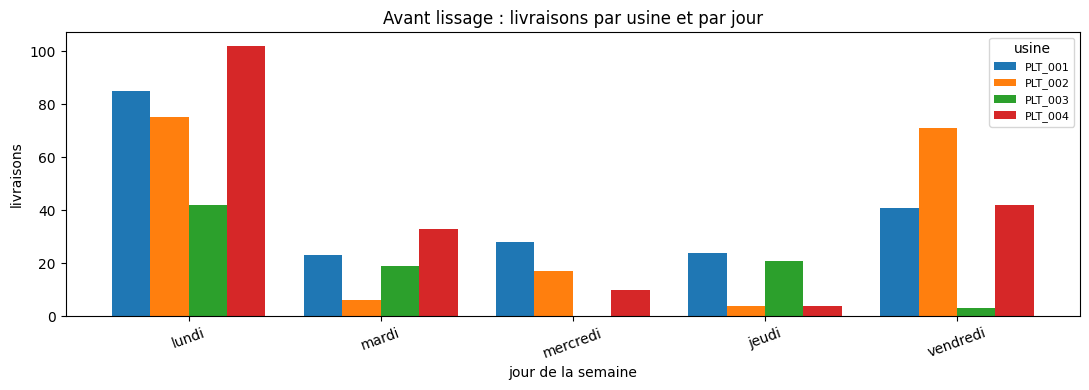

In [16]:
def charge_par_jour_semaine(choix):
    """Nombre de livraisons reelles par usine et par jour de la semaine."""
    t = defaultdict(lambda: defaultdict(int))
    for (s, pl), b in choix.items():
        for d in b["jours"]:
            t[pl][pd.Timestamp(d).weekday()] += 1
    return t

def tracer_charge(t, titre, ax):
    """Barres groupees : livraisons par usine pour chaque jour de la semaine."""
    usines = sorted(t.keys()); x = np.arange(5); larg = 0.8 / max(len(usines), 1)
    for i, u in enumerate(usines):
        vals = [t[u].get(j, 0) for j in range(5)]
        ax.bar(x + (i - (len(usines) - 1) / 2) * larg, vals, width=larg, label=u)
    ax.set_title(titre); ax.set_xlabel("jour de la semaine"); ax.set_ylabel("livraisons")
    ax.set_xticks(x); ax.set_xticklabels([JOURS[j] for j in range(5)], rotation=20)
    ax.legend(title="usine", fontsize=8)

fig, ax = plt.subplots(figsize=(11, 4))
tracer_charge(charge_par_jour_semaine(meilleur), "Avant lissage : livraisons par usine et par jour", ax)
plt.tight_layout(); plt.show()

**Notre règle de lissage**, usine par usine (glouton), corrige un biais : à
coût égal, c'est aujourd'hui le premier profil testé qui gagne, et il commence le
**lundi**, ce qui **charge les lundis**. Nouvelle règle :

- nous traitons les couples **du plus coûteux au moins coûteux** ;
- pour chaque couple, nous gardons les profils dont le coût dépasse son meilleur de
  **2 % au plus** (H17) ;
- parmi eux, nous choisissons celui qui **charge le moins le jour déjà le plus chargé**
  de l'usine (puis le plus petit maximum, le plus petit écart-type, le coût, le moins
  de livraisons) ;
- nous ajoutons ses livraisons à la charge de l'usine, et passons au couple suivant.

APRES LISSAGE (tolerance 2% )
  cout      : 82110.82 EUR
  ajout vs etape 1 : 148.04 EUR ( 0.181 % )
  part des livraisons du lundi : avant 46.8% -> apres 25.2%


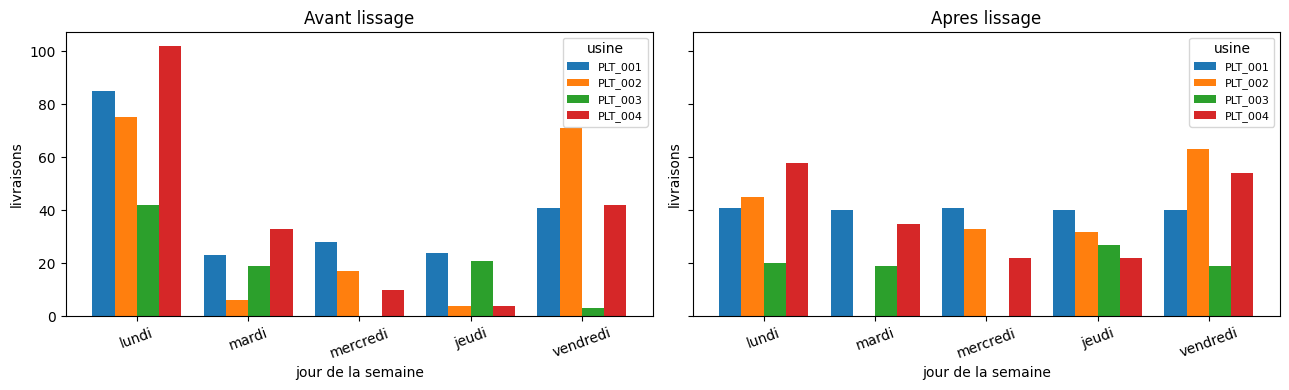

In [17]:
def lissage(candidats, meilleur, tolerance):
    """Choisit par usine un profil dans la tolerance qui decharge le jour deja le plus charge (R4)."""
    choix = {}; cout = 0.0
    for usine in sorted({pl for (s, pl) in candidats}):
        couples_u = [c for c in candidats if c[1] == usine and candidats[c]]
        couples_u.sort(key=lambda c: -meilleur[c]["cout"])     # du plus cher au moins cher
        charge = defaultdict(int)                               # livraisons par jour de la semaine
        for c in couples_u:
            seuil = meilleur[c]["cout"] * (1 + tolerance) + 1e-9
            toleres = [r for r in candidats[c] if r["cout"] <= seuil]
            pic = max(charge.values()) if charge else 0
            jours_pic = {j for j, v in charge.items() if v == pic}
            def cle_tri(r):
                wd = [pd.Timestamp(d).weekday() for d in r["jours"]]
                ajout_pic = sum(1 for j in wd if j in jours_pic)     # charge ajoutee au jour le plus charge
                essai = dict(charge)
                for j in wd:
                    essai[j] = essai.get(j, 0) + 1
                vec = np.array(list(essai.values())) if essai else np.array([0])
                return (ajout_pic, int(vec.max()), float(vec.std()), r["cout"], r["livraisons"])
            choisi = min(toleres, key=cle_tri)
            choix[c] = choisi; cout += choisi["cout"]
            for d in choisi["jours"]:
                charge[pd.Timestamp(d).weekday()] += 1
    return choix, cout

choix_final, cout_final = lissage(CANDIDATS, meilleur, TOLERANCE_LISSAGE)
ajout = cout_final - cout_etape1

def part_lundi(choix):
    lun = tot = 0
    for b in choix.values():
        for d in b["jours"]:
            tot += 1
            if pd.Timestamp(d).weekday() == 0:
                lun += 1
    return lun, tot, (lun / tot * 100 if tot else 0)

l_av = part_lundi(meilleur); l_ap = part_lundi(choix_final)
print("APRES LISSAGE (tolerance", f"{TOLERANCE_LISSAGE:.0%}", ")")
print("  cout      :", round(cout_final, 2), "EUR")
print("  ajout vs etape 1 :", round(ajout, 2), "EUR (", round(ajout / cout_etape1 * 100, 3), "% )")
print("  part des livraisons du lundi : avant", f"{l_av[2]:.1f}%", "-> apres", f"{l_ap[2]:.1f}%")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
tracer_charge(charge_par_jour_semaine(meilleur), "Avant lissage", a1)
tracer_charge(charge_par_jour_semaine(choix_final), "Apres lissage", a2)
plt.tight_layout(); plt.show()

**Notre constat :** le lissage n'ajoute que **148 €** (**+0,18 %**), un coût presque
nul. En échange, la semaine est bien plus régulière : la **part des livraisons du lundi
tombe de 46,8 % à 25,2 %**. Le graphique le montre : avant, les barres du lundi dominent ;
après, les cinq jours se ressemblent. Nous respectons R4 sans sacrifier l'économie. Le
lissage est le même dans les trois versions : il choisit parmi les profils possibles de
la version choisie.

## Section 7 : Les solutions comparées, et notre choix

Nous comparons, à **règles égales** (H20 appliqué partout), les baselines, l'ancien
moteur et les deux étapes de notre moteur dans la version choisie. Toutes les économies
sont mesurées par rapport à la **baseline avec H20**. Les trois versions sont comparées
entre elles plus loin, avant le bilan.

,solution,cout,camions,livraisons,economie EUR,economie %
0,baseline milestone 2,143422.43,1604,1599,-101.69,-0.1
1,baseline avec H20,143320.74,1604,1599,0.00,0.0
2,moteur sans H19 ni H21,81223.15,648,636,62097.59,43.3
3,"etape 1, version strict",81962.78,651,650,61357.96,42.8
4,"apres lissage, version strict (RETENUE)",82110.82,652,651,61209.92,42.7


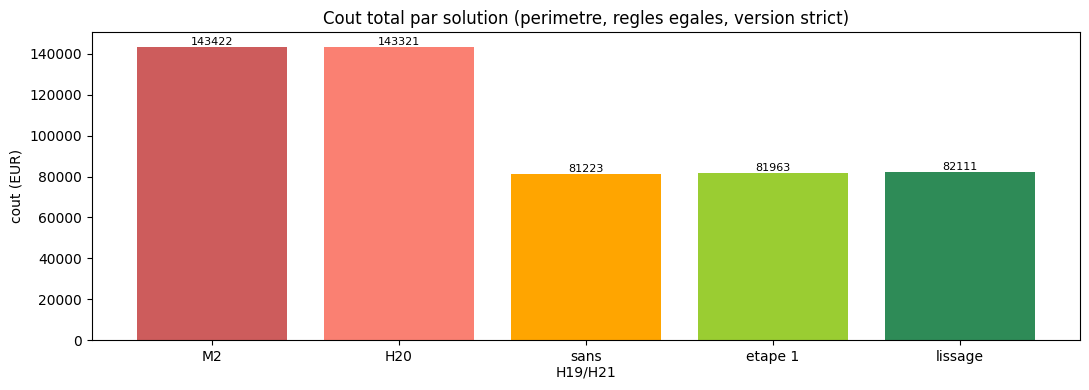

In [18]:
def totaux(choix):
    return (sum(b["cout"] for b in choix.values()), sum(b["camions"] for b in choix.values()),
            sum(b["livraisons"] for b in choix.values()))

# moteur sans H19 ni H21 (ancien : plusieurs camions par jour, tous les jours du profil)
cand_anc = evaluer_tous(idx_tous, un_camion=False)
best_anc = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand_anc.items() if v}

liv_actuel = opt.groupby(["supplier_id", "plant", "date"]).ngroups
rows = [
    ("baseline milestone 2", baseline_M2, camions_M2, liv_actuel),
    ("baseline avec H20", baseline_H20, camions_H20, liv_actuel),
    ("moteur sans H19 ni H21", *totaux(best_anc)),
    (f"etape 1, version {MODE_PROFIL}", *totaux(meilleur)),
    (f"apres lissage, version {MODE_PROFIL} (RETENUE)", *totaux(choix_final)),
]
comparaison = pd.DataFrame([{"solution": n, "cout": round(c, 2), "camions": cam, "livraisons": liv,
                             "economie EUR": round(baseline_H20 - c, 2),
                             "economie %": round((baseline_H20 - c) / baseline_H20 * 100, 1)}
                            for n, c, cam, liv in rows])
display(comparaison)

fig, ax = plt.subplots(figsize=(11, 4))
noms = ["M2", "H20", "sans\nH19/H21", "etape 1", "lissage"]
barres = ax.bar(noms, comparaison["cout"], color=["indianred", "salmon", "orange", "yellowgreen", "seagreen"])
ax.set_title(f"Cout total par solution (perimetre, regles egales, version {MODE_PROFIL})"); ax.set_ylabel("cout (EUR)")
for b, v in zip(barres, comparaison["cout"]):
    ax.text(b.get_x() + b.get_width() / 2, v, str(round(v)), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

**Notre choix : la solution après lissage, en version stricte**, notre version
recommandée par défaut. Un **profil proposé est un engagement** envers le fournisseur :
s'il annonce deux passages par semaine, il vient deux fois, et un jour du profil sans rien
à livrer n'envoie pas de camion. La version stricte tient ce rythme **chaque semaine**.
Elle respecte toutes les règles, garde **42,7 %** d'économie (**61 210 €** sur la baseline
avec H20) et équilibre la semaine.

Un camion par jour (H19) en version stricte coûte **82 111 €**, à peine plus que l'ancien
moteur à plusieurs camions par jour (**81 223 €**, 43,3 %) : pour moins de 1 000 € d'écart,
nous ne coupons jamais une ligne et nous tenons le rythme annoncé. Les versions **libre**
et **intermédiaire** montrent ce que coûterait plus de souplesse (comparaison des trois
versions avant le bilan).

**Étude de sensibilité.** Nous regardons l'effet de nos réglages : la tolérance
de lissage (H17), l'avance maximale (R1 reste 7 jours, pour information), et nos
réglages H19 et H21 (un camion par jour, et les trois versions du profil).

In [19]:
sens_tol = []
for tol in (0.0, 0.02, 0.05):
    ch, co = lissage(CANDIDATS, meilleur, tol)
    sens_tol.append({"TOLERANCE_LISSAGE": f"{tol:.0%}", "cout": round(co, 2),
                     "part lundi %": round(part_lundi(ch)[2], 1)})
print("Tolerance de lissage (H17) :"); display(pd.DataFrame(sens_tol))

sens_av = []
for am in (7, 14):
    # re-evaluer avec une autre avance : on change AVANCE_MAX temporairement
    globals()["AVANCE_MAX"] = am
    cand_am = evaluer_tous(idx_tous)
    best_am = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand_am.items() if v}
    sens_av.append({"AVANCE_MAX": f"{am} jours", "cout": round(sum(b["cout"] for b in best_am.values()), 2),
                    "sans solution": sum(len(v) == 0 for v in cand_am.values())})
globals()["AVANCE_MAX"] = 7
print(f"Avance maximale (R1 reste 7 jours), version {MODE_PROFIL} :"); display(pd.DataFrame(sens_av))

sens_regle = []
for uc, mode, nom in [(False, "strict", "sans H19 ni H21"), (True, "strict", "H19, version strict"),
                      (True, "intermediaire", "H19, version intermediaire"), (True, "libre", "H19, version libre")]:
    cand = evaluer_tous(idx_tous, un_camion=uc, mode=mode)
    best = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand.items() if v}
    sens_regle.append({"UN_CAMION_PAR_JOUR": uc, "MODE_PROFIL": mode if uc else "(tous les jours)", "libelle": nom,
                       "cout etape 1": round(sum(b["cout"] for b in best.values()), 2),
                       "camions": sum(b["camions"] for b in best.values())})
print("Reglages H19 et H21 (etape 1, avant lissage) :"); display(pd.DataFrame(sens_regle))

Tolerance de lissage (H17) :


,TOLERANCE_LISSAGE,cout,part lundi %
0,0%,81962.78,26.0
1,2%,82110.82,25.2
2,5%,82560.24,21.2


Avance maximale (R1 reste 7 jours), version strict :


,AVANCE_MAX,cout,sans solution
0,7 jours,81962.78,0
1,14 jours,60478.16,0


Reglages H19 et H21 (etape 1, avant lissage) :


,UN_CAMION_PAR_JOUR,MODE_PROFIL,libelle,cout etape 1,camions
0,False,(tous les jours),sans H19 ni H21,81223.15,648
1,True,strict,"H19, version strict",81962.78,651
2,True,intermediaire,"H19, version intermediaire",79017.07,617
3,True,libre,"H19, version libre",74843.82,567


**Notre constat :** augmenter la tolérance de 0 % à 5 % change peu le coût
(**81 963 € à 82 560 €**) et aide un peu le lissage (part du lundi de **26,0 % à
21,2 %**). L'essentiel du lissage vient de la **règle de choix elle-même** : même à 0 %
de tolérance, elle fait tomber le lundi de 46,8 % à 26,0 %. Nous gardons **2 %** comme
petite marge. Passer l'avance à 14 jours ferait tomber le coût à **60 478 €**, mais
violerait R1 ; nous ne le retenons pas.

Le tableau des réglages montre l'effet de chaque règle à l'étape 1. **H19 en version
stricte** coûte un peu plus que l'ancien moteur (**81 963 €** contre **81 223 €**), car un
camion par jour oblige à plus de livraisons. Pouvoir sauter des jours du profil fait
baisser le coût : **79 017 €** en version intermédiaire, **74 844 €** en version libre.
Cette liberté apporte l'essentiel du gain, mais elle se paie en régularité : c'est le prix
de l'engagement pris envers le fournisseur.

## Section 8 : Nos fonctions de validation

Avant d'annoncer un résultat, nous le **vérifions**. Nous reconstruisons d'abord le
contenu détaillé des camions de la solution retenue (une ligne n'étant jamais coupée,
chaque ligne tient dans un seul camion), puis nous passons tous les contrôles.

In [20]:
def reconstruire(cle, b):
    """Contenu des camions d'un couple pour le profil choisi b : liste de camions (date, exceptionnel, lignes)."""
    couple = COUPLES[cle]; dates = DATES_PROFIL[b["idx"]]; trucks = []
    # envois exceptionnels (H20) : une ligne, un camion, jour du profil le plus proche <= besoin
    for e in range(len(couple["exc_dates"])):
        bd = couple["exc_dates"][e]
        k = int(np.searchsorted(dates, bd, side="right")) - 1
        trucks.append({"date": pd.Timestamp(dates[k]), "exceptionnel": True, "lignes": [{
            "material": couple["exc_mat"][e], "unloading_point": couple["exc_up"][e],
            "date_besoin": pd.Timestamp(bd), "quantite": float(couple["exc_qte"][e]),
            "poids": float(couple["exc_poids"][e]), "volume": float(couple["exc_vol"][e])}]})
    besoins = couple["besoins"]
    if len(besoins) == 0:
        return trucks
    def truck(jour, idxs):
        lignes = [{"material": couple["mat"][i], "unloading_point": couple["up"][i],
                   "date_besoin": pd.Timestamp(couple["besoins"][i]), "quantite": float(couple["qte"][i]),
                   "poids": float(couple["poids"][i]), "volume": float(couple["volume"][i])} for i in idxs]
        return {"date": pd.Timestamp(jour), "exceptionnel": False, "lignes": lignes}
    if "affect" in b:                                         # 3 couples aux jours trop lourds : ligne -> jour
        for k in sorted(b["affect"]):
            trucks.append(truck(dates[k], b["affect"][k]))
    else:                                                    # DP ou strict : chaque besoin au dernier jour livre <= lui
        jours = np.sort(b["jours"])
        jj = jours.astype("datetime64[D]").astype(int); bjours = besoins.astype("datetime64[D]").astype(int)
        pos = np.searchsorted(jj, bjours, side="right") - 1
        par_jour = defaultdict(list)
        for i in range(len(besoins)):
            par_jour[int(pos[i])].append(i)
        for k, idxs in par_jour.items():
            trucks.append(truck(jours[k], idxs))
    return trucks

def construire_contenu(choix):
    """Sortie 2 : une ligne par ligne de besoin chargee, avec son camion."""
    lignes_camions = []; numero = 0
    for (s, pl), b in choix.items():
        for t in reconstruire((s, pl), b):
            numero += 1; cid = f"C{numero:05d}"
            for L in t["lignes"]:
                lignes_camions.append({"camion_id": cid, "supplier_id": s, "plant": pl,
                    "date_livraison": t["date"].date(), "material": L["material"],
                    "unloading_point": L["unloading_point"], "date_besoin": L["date_besoin"].date(),
                    "avance_jours": (L["date_besoin"] - t["date"]).days, "quantite": round(L["quantite"], 3),
                    "poids": round(L["poids"], 3), "volume": round(L["volume"], 4),
                    "envoi_exceptionnel": t["exceptionnel"]})
    return pd.DataFrame(lignes_camions)

contenu_camions = construire_contenu(choix_final)
print(f"Camions de la solution retenue (version {MODE_PROFIL}) :", contenu_camions["camion_id"].nunique(),
      "| lignes chargees :", len(contenu_camions),
      "| dont exceptionnels :", int(contenu_camions["envoi_exceptionnel"].sum()))

Camions de la solution retenue (version strict) : 652 | lignes chargees : 4252 | dont exceptionnels : 1


In [21]:
def en_jours(serie):
    """Dates -> nombre de jours (entiers), pour comparer avec les dates du profil."""
    return pd.to_datetime(serie).values.astype("datetime64[D]").astype(int)

def semaines_par_couple(choix, contenu):
    """(semaines respectees, semaines du profil) de chaque couple, lues sur le contenu des camions."""
    normal = contenu[~contenu["envoi_exceptionnel"]]
    groupes = {k: g for k, g in normal.groupby(["supplier_id", "plant"])}
    res = {}
    for cle, b in choix.items():
        g = groupes.get(cle)
        liv = en_jours(g["date_livraison"]) if g is not None else []
        bes = en_jours(g["date_besoin"]) if g is not None else []
        res[cle] = semaines_respectees(b["idx"], liv, bes)
    return res

def valider(choix, contenu, cout_annonce, mode=None, afficher=True):
    """Passe tous les controles de la solution ; s'arrete si un echoue."""
    mode = MODE_PROFIL if mode is None else mode
    controles = []
    normal = contenu[~contenu["envoi_exceptionnel"]]
    excep = contenu[contenu["envoi_exceptionnel"]]
    par_couple = {k: g for k, g in contenu.groupby(["supplier_id", "plant"])}
    # 1. chaque ligne livree une seule fois ; poids et volume conserves
    c1 = (len(contenu) == len(opt) and abs(opt["weight"].sum() - contenu["poids"].sum()) < 1
          and abs(opt["volume"].sum() - contenu["volume"].sum()) < 0.1)
    controles.append(("chaque ligne livree une fois (poids et volume conserves)", bool(c1)))
    # 2. aucune ligne coupee : une ligne = une seule occurrence
    c2 = not contenu.duplicated(subset=["supplier_id", "plant", "material", "unloading_point", "date_besoin"]).any()
    controles.append(("aucune ligne coupee", bool(c2)))
    # 3. avance entre 0 et 7 jours
    av = contenu["avance_jours"]
    controles.append(("avance entre 0 et 7 jours", bool((av >= 0).all() and (av <= AVANCE_MAX).all())))
    # 4. jours ouvres, hors semaine fermee, dans l'horizon
    dl = pd.to_datetime(contenu["date_livraison"])
    controles.append(("lundi-vendredi, hors semaine fermee, dans l'horizon",
                      bool((dl.dt.weekday < 5).all() and (~dl.map(semaine_fermee)).all() and (dl >= d0).all())))
    # 5. capacite des camions normaux
    cap = normal.groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
    controles.append(("capacite 24 500 kg / 110,4 m3 (camions normaux)",
                      bool((cap["p"] <= CAP_POIDS + 1e-3).all() and (cap["v"] <= CAP_VOLUME + 1e-3).all())))
    # 6. un seul couple par camion (R3)
    controles.append(("un seul couple par camion (R3)",
                      bool((contenu.groupby("camion_id")[["supplier_id", "plant"]].nunique() <= 1).all().all())))
    # 7. au plus un camion par couple et par jour, hors exceptionnels (H19)
    c7 = (normal.groupby(["supplier_id", "plant", "date_livraison"])["camion_id"].nunique() <= 1).all()
    controles.append(("au plus un camion par couple et par jour (H19)", bool(c7)))
    # 8. chaque date de livraison est une date exacte du profil choisi ; par semaine <= nombre du profil
    c8 = True
    for cle, b in choix.items():
        dates_p = DATES_PROFIL[b["idx"]].astype("datetime64[D]").astype(int)
        g = par_couple.get(cle)
        if g is None:
            continue
        if not np.isin(en_jours(g["date_livraison"]), dates_p).all():
            c8 = False
        dts = pd.to_datetime(g[~g["envoi_exceptionnel"]]["date_livraison"].unique())
        par_sem = Counter(semaine_de(d) for d in dts)
        nb_profil = Counter(semaine_de(d) for d in DATES_PROFIL[b["idx"]])
        if any(par_sem[w] > nb_profil.get(w, 0) for w in par_sem):
            c8 = False
    controles.append(("livraisons aux dates exactes du profil, <= nombre du profil par semaine", c8))
    # 9. chaque envoi exceptionnel : une seule ligne plus lourde qu'un camion
    c9 = True
    for cid, g in excep.groupby("camion_id"):
        if len(g) != 1 or not (g["poids"].iloc[0] > CAP_POIDS or g["volume"].iloc[0] > CAP_VOLUME):
            c9 = False
    controles.append(("chaque envoi exceptionnel = une ligne plus lourde qu'un camion", c9))
    # 10. les jours trop lourds (3 couples) couverts sans depasser la capacite
    c10 = True
    for (s, pl) in COUPLES_CAP:
        sous = normal[(normal.supplier_id == s) & (normal.plant == pl)]
        if len(sous) != len(COUPLES[(s, pl)]["besoins"]):
            c10 = False
        capc = sous.groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
        if not ((capc["p"] <= CAP_POIDS + 1e-3).all() and (capc["v"] <= CAP_VOLUME + 1e-3).all()):
            c10 = False
    controles.append(("jours trop lourds couverts sans depasser la capacite", c10))
    # 11. jamais de camion vide : les camions annonces sont exactement les camions charges
    c11 = contenu["camion_id"].nunique() == sum(b["camions"] for b in choix.values())
    controles.append(("aucun camion vide (camions annonces = camions charges)", bool(c11)))
    # 12. cout recalcule == cout annonce
    recalc = 0.0
    for cid, g in contenu.groupby("camion_id"):
        lg = COUPLES[(g["supplier_id"].iloc[0], g["plant"].iloc[0])]["ligne"]
        recalc += prix_exceptionnel(lg) if g["envoi_exceptionnel"].iloc[0] else prix_camion(lg, g["poids"].sum())
    controles.append(("cout coherent avec les camions", abs(recalc - cout_annonce) < 1))
    # 13. la regle de la version choisie
    if mode == "strict":
        c13 = True                       # chaque jour du profil qui a quelque chose a livrer est livre
        for cle, b in choix.items():
            g = par_couple.get(cle)
            if g is None:
                continue
            gn = g[~g["envoi_exceptionnel"]]
            dates_p = DATES_PROFIL[b["idx"]].astype("datetime64[D]").astype(int)
            bes = en_jours(gn["date_besoin"]); livres = set(en_jours(gn["date_livraison"]))
            pos = np.searchsorted(dates_p, bes, side="right") - 1      # le jour du profil de chaque besoin
            if any(int(dates_p[k]) not in livres for k in np.unique(pos)):
                c13 = False
        controles.append(("version strict : chaque jour du profil qui a quelque chose a livrer est livre", c13))
    elif mode == "intermediaire":
        sem = semaines_par_couple(choix, contenu)
        c13 = all(sem[cle][0] >= objectif_semaines(b["idx"])[0] for cle, b in choix.items())
        controles.append((f"version intermediaire : au moins {MIN_SEMAINES_RESPECTEES} semaines respectees "
                          "par couple (toutes si le profil en a moins)", c13))
    else:
        controles.append(("version libre : le profil est un maximum (dates deja verifiees au controle 8)", c8))
    if afficher:
        for nom, okc in controles:
            print(f"  [{'OK' if okc else 'ECHEC'}] {nom}")
    if not all(okc for _, okc in controles):
        for nom, okc in controles:
            if not okc:
                print(f"  [ECHEC] {nom}")
        raise AssertionError("Une validation a echoue : nous ne publions pas ce resultat.")
    print(f"Toutes les validations passent ({len(controles)} controles, version {mode}).")
    return len(controles)

nb_controles = valider(choix_final, contenu_camions, cout_final)

  [OK] chaque ligne livree une fois (poids et volume conserves)
  [OK] aucune ligne coupee
  [OK] avance entre 0 et 7 jours
  [OK] lundi-vendredi, hors semaine fermee, dans l'horizon
  [OK] capacite 24 500 kg / 110,4 m3 (camions normaux)
  [OK] un seul couple par camion (R3)
  [OK] au plus un camion par couple et par jour (H19)
  [OK] livraisons aux dates exactes du profil, <= nombre du profil par semaine
  [OK] chaque envoi exceptionnel = une ligne plus lourde qu'un camion
  [OK] jours trop lourds couverts sans depasser la capacite
  [OK] aucun camion vide (camions annonces = camions charges)
  [OK] cout coherent avec les camions
  [OK] version strict : chaque jour du profil qui a quelque chose a livrer est livre
Toutes les validations passent (13 controles, version strict).


**Notre constat :** les **treize contrôles passent** pour la version choisie
(**stricte**). Chaque ligne est livrée une fois sans être coupée, jamais en retard ni plus
de 7 jours en avance, uniquement en semaine, sans dépasser la capacité, avec **au plus un
camion par couple et par jour** (H19). Chaque livraison tombe sur une **date exacte** du
profil choisi (et pas seulement le bon jour de la semaine), sans dépasser le rythme du
profil. L'unique envoi exceptionnel est bien une ligne trop lourde seule, les jours trop
lourds sont couverts, **aucun camion n'est vide**, et le coût recalculé colle au coût
annoncé. Le dernier contrôle vérifie la règle de la version : en strict, **chaque jour du
profil qui a quelque chose à livrer est livré**. Notre résultat est fiable.

## Section 9 : Nos résultats

Cout       : avant 143320.74 -> apres 82110.82 EUR  ( 61209.92 EUR, 42.7 % )
Camions    : avant 1604 -> apres 652
Livraisons : avant 1599 -> apres 651
Objectif (au moins 35 %) : ATTEINT


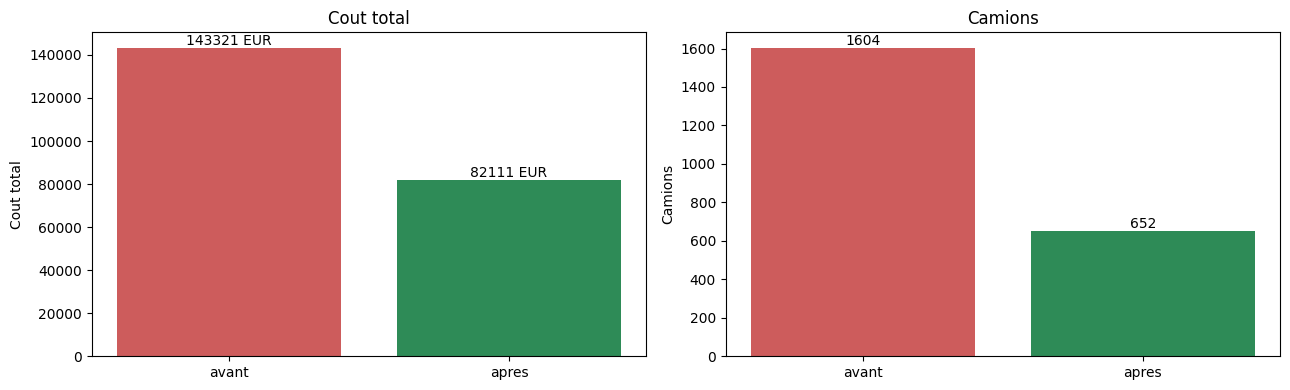

In [22]:
gain = baseline_H20 - cout_final
livraisons_avant = opt.groupby(["supplier_id", "plant", "date"]).ngroups
livraisons_apres = sum(b["livraisons"] for b in choix_final.values())
camions_apres = sum(b["camions"] for b in choix_final.values())
print("Cout       : avant", round(baseline_H20, 2), "-> apres", round(cout_final, 2),
      "EUR  (", round(gain, 2), "EUR,", round(gain / baseline_H20 * 100, 1), "% )")
print("Camions    : avant", camions_H20, "-> apres", camions_apres)
print("Livraisons : avant", livraisons_avant, "-> apres", livraisons_apres)
print("Objectif (au moins 35 %) :", "ATTEINT" if gain / baseline_H20 * 100 >= 35 else "non atteint")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for ax, vals, titre, unite in [(a1, [baseline_H20, cout_final], "Cout total", " EUR"),
                               (a2, [camions_H20, camions_apres], "Camions", "")]:
    barres = ax.bar(["avant", "apres"], vals, color=["indianred", "seagreen"])
    ax.set_title(titre); ax.set_ylabel(titre)
    for b, v in zip(barres, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, str(round(v)) + unite, ha="center", va="bottom")
plt.tight_layout(); plt.show()

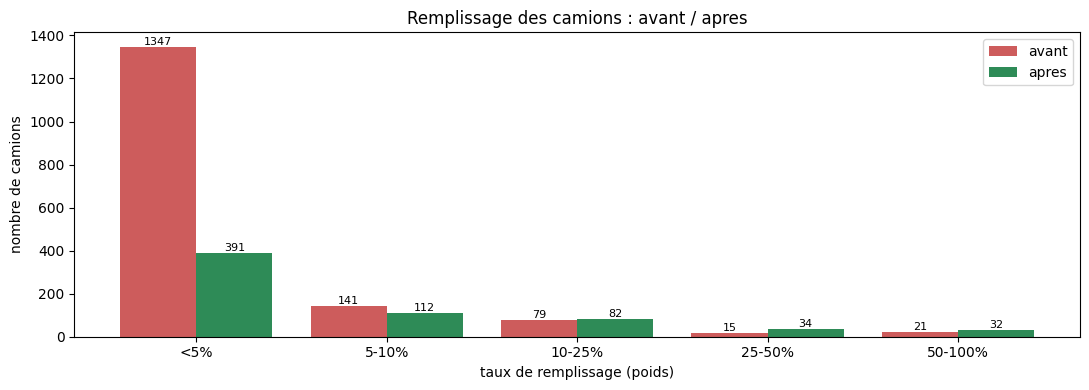

Remplissage median : avant 1.33 % -> apres 2.91 %
Camions sous 5 % : avant 1347 -> apres 391


In [23]:
# Remplissage des camions (poids), avant et apres. Avant = baseline H20 (hors camion exceptionnel).
remp_avant = []
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    exc = (g["weight"].values > CAP_POIDS) | (g["volume"].values > CAP_VOLUME)
    nn = g[~exc]
    if len(nn):
        remp_avant += [w / CAP_POIDS * 100 for w in charger_camions_vieux(nn["weight"].values, nn["volume"].values)]
remp_apres = [g["poids"].sum() / CAP_POIDS * 100
              for cid, g in contenu_camions[~contenu_camions["envoi_exceptionnel"]].groupby("camion_id")]

bornes = [0, 5, 10, 25, 50, 100.0001]; libelles = ["<5%", "5-10%", "10-25%", "25-50%", "50-100%"]
ca = pd.cut(remp_avant, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
cb = pd.cut(remp_apres, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
x = np.arange(len(libelles))
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, ca.values, width=0.4, label="avant", color="indianred")
ax.bar(x + 0.2, cb.values, width=0.4, label="apres", color="seagreen")
ax.set_title("Remplissage des camions : avant / apres"); ax.set_xlabel("taux de remplissage (poids)")
ax.set_ylabel("nombre de camions"); ax.set_xticks(x); ax.set_xticklabels(libelles); ax.legend()
for i, v in enumerate(ca.values): ax.text(i - 0.2, v, str(int(v)), ha="center", va="bottom", fontsize=8)
for i, v in enumerate(cb.values): ax.text(i + 0.2, v, str(int(v)), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
print("Remplissage median : avant", round(np.median(remp_avant), 2), "% -> apres", round(np.median(remp_apres), 2), "%")
print("Camions sous 5 % : avant", sum(1 for r in remp_avant if r < 5), "-> apres", sum(1 for r in remp_apres if r < 5))

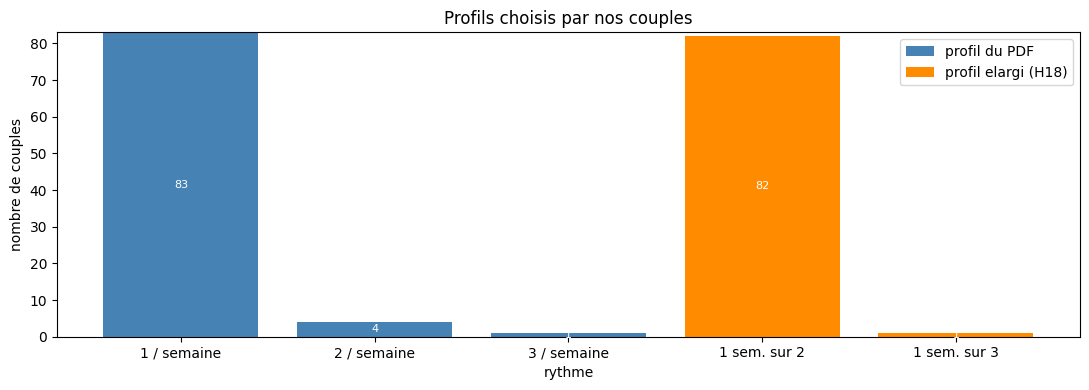

Couples avec un profil elargi (H18) : 83 sur 171


In [24]:
# Profils choisis, par rythme, en distinguant PDF et profils elargis.
def rythme(p):
    return f"{len(p['jours'])} / semaine" if p["periode"] == 1 else f"1 sem. sur {p['periode']}"

compte = defaultdict(lambda: [0, 0])
for b in choix_final.values():
    p = PROFILS[b["idx"]]; compte[rythme(p)][0 if p["type"] == "PDF" else 1] += 1
ordre = sorted(compte, key=lambda r: (len(r), r))
pdfv = [compte[r][0] for r in ordre]; elav = [compte[r][1] for r in ordre]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(ordre, pdfv, label="profil du PDF", color="steelblue")
ax.bar(ordre, elav, bottom=pdfv, label="profil elargi (H18)", color="darkorange")
ax.set_title("Profils choisis par nos couples"); ax.set_xlabel("rythme"); ax.set_ylabel("nombre de couples")
for i, (a, b2) in enumerate(zip(pdfv, elav)):
    if a: ax.text(i, a / 2, str(a), ha="center", va="center", color="white", fontsize=8)
    if b2: ax.text(i, a + b2 / 2, str(b2), ha="center", va="center", color="white", fontsize=8)
ax.legend(); plt.tight_layout(); plt.show()
print("Couples avec un profil elargi (H18) :", sum(elav), "sur", len(choix_final))

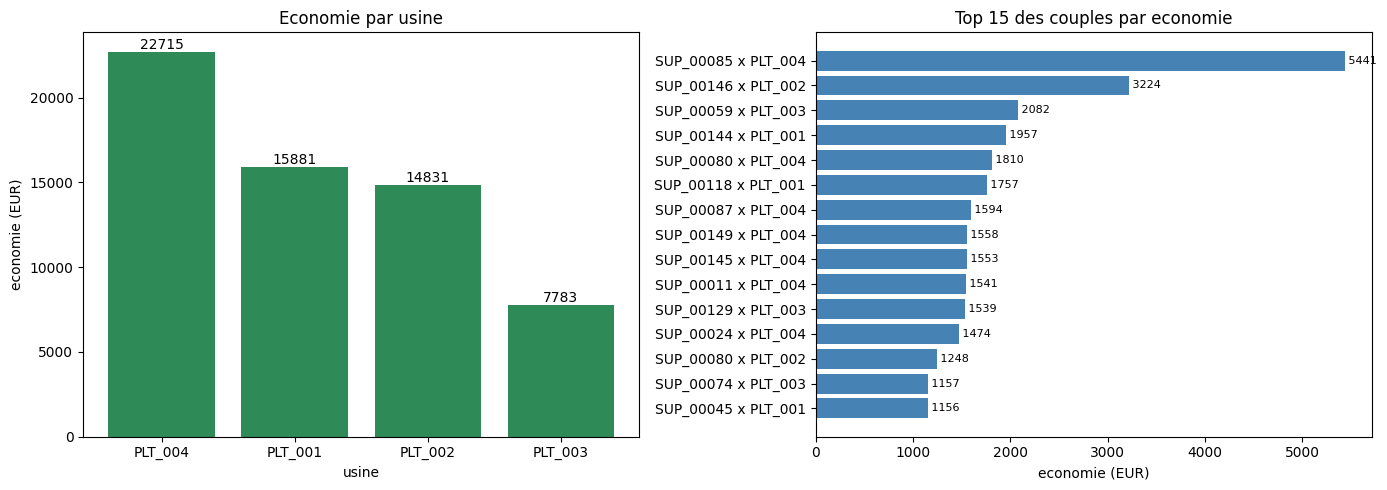

Economie par usine (EUR) : {'PLT_004': 22714.79, 'PLT_001': 15880.85, 'PLT_002': 14830.89, 'PLT_003': 7783.39}
Couple le plus rentable : SUP_00085 x PLT_004 -> 5440.74 EUR


In [25]:
# Economie par usine et top 15 des couples (vs part baseline H20 de chaque couple).
def cout_actuel_couple(cle):
    g = COUPLES[cle]["df"]; lg = COUPLES[cle]["ligne"]; c = 0.0
    for dt, gg in g.groupby("date"):
        exc = (gg["weight"].values > CAP_POIDS) | (gg["volume"].values > CAP_VOLUME)
        nn = gg[~exc]
        if len(nn):
            c += sum(prix_camion(lg, w) for w in charger_camions_vieux(nn["weight"].values, nn["volume"].values))
        c += int(exc.sum()) * prix_exceptionnel(lg)
    return c

eco = pd.DataFrame([{"supplier_id": s, "plant": pl, "eco": cout_actuel_couple((s, pl)) - choix_final[(s, pl)]["cout"]}
                    for (s, pl) in COUPLES])
eco_usine = eco.groupby("plant")["eco"].sum().sort_values(ascending=False)
top15 = eco.sort_values("eco", ascending=False).head(15)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
barres = a1.bar(eco_usine.index, eco_usine.values, color="seagreen")
a1.set_title("Economie par usine"); a1.set_xlabel("usine"); a1.set_ylabel("economie (EUR)")
for b, v in zip(barres, eco_usine.values): a1.text(b.get_x() + b.get_width() / 2, v, str(round(v)), ha="center", va="bottom")
etiq = top15["supplier_id"] + " x " + top15["plant"]
a2.barh(etiq, top15["eco"], color="steelblue"); a2.invert_yaxis()
a2.set_title("Top 15 des couples par economie"); a2.set_xlabel("economie (EUR)")
for i, v in enumerate(top15["eco"]): a2.text(v, i, " " + str(round(v)), va="center", fontsize=8)
plt.tight_layout(); plt.show()
print("Economie par usine (EUR) :", {u: round(v, 2) for u, v in eco_usine.items()})
print("Couple le plus rentable :", top15.iloc[0]["supplier_id"], "x", top15.iloc[0]["plant"],
      "->", round(top15.iloc[0]["eco"], 2), "EUR")

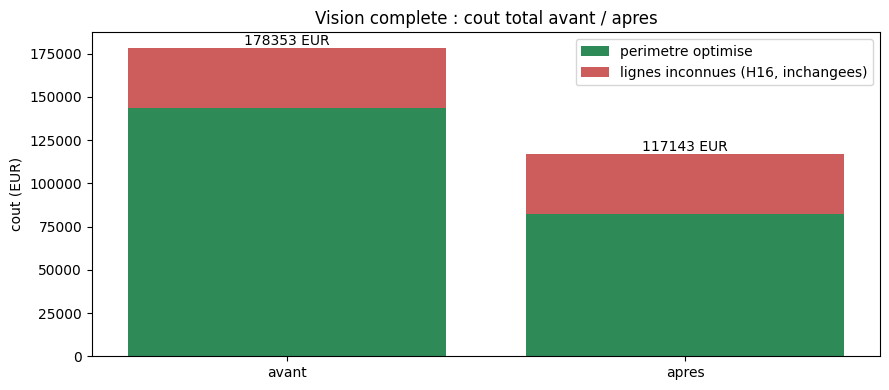

Cout total (avec inconnues) : avant 178353.16 -> apres 117143.24 EUR


In [26]:
# Vision complete : en ajoutant les lignes inconnues (identiques avant et apres).
COUT_INCONNUES = 35032.42   # H16, calcule au milestone 2
avant_total = baseline_H20 + COUT_INCONNUES
apres_total = cout_final + COUT_INCONNUES
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(["avant", "apres"], [baseline_H20, cout_final], color="seagreen", label="perimetre optimise")
ax.bar(["avant", "apres"], [COUT_INCONNUES, COUT_INCONNUES], bottom=[baseline_H20, cout_final],
       color="indianred", label="lignes inconnues (H16, inchangees)")
ax.set_title("Vision complete : cout total avant / apres"); ax.set_ylabel("cout (EUR)")
for i, tot in enumerate([avant_total, apres_total]):
    ax.text(i, tot, str(round(tot)) + " EUR", ha="center", va="bottom")
ax.legend(); plt.tight_layout(); plt.show()
print("Cout total (avec inconnues) : avant", round(avant_total, 2), "-> apres", round(apres_total, 2), "EUR")

**Notre constat :** en version **stricte**, sur le périmètre, nous passons de
**143 321 €** à **82 111 €**, soit **61 210 € (42,7 %) d'économie** : l'objectif des
35 % est largement **dépassé**. Nous divisons les camions (1 604 -> 652) et les
livraisons (1 599 -> 651). Le remplissage médian d'un camion passe de **1,33 % à
2,91 %**, et les camions sous 5 % fondent de **1 347 à 391**. L'usine **PLT_004**
concentre la plus grosse économie (**22 715 €**) ; le couple le plus rentable,
**SUP_00085 x PLT_004**, économise **5 441 €** à lui seul. **83 couples** choisissent un
profil élargi (H18). Vision complète, lignes inconnues comprises, nous passons de
**178 353 €** à **117 143 €**.

## Section 10 : Nos sorties

Notre moteur produit deux sorties, plus un résumé des économies, pour la version
choisie (`MODE_PROFIL`). Le tableau des trois versions est enregistré à part
(`comparaison_versions.csv`, dans la comparaison avant le bilan).

In [27]:
# Sortie 1 : un profil par couple, avec le nombre de livraisons reelles.
lignes1 = []
for (s, pl), b in choix_final.items():
    couple = COUPLES[(s, pl)]; p = PROFILS[b["idx"]]
    cout_act = cout_actuel_couple((s, pl))
    poids_cams = [g["poids"].sum() for cid, g in
                  contenu_camions[(contenu_camions.supplier_id == s) & (contenu_camions.plant == pl)
                                  & (~contenu_camions.envoi_exceptionnel)].groupby("camion_id")]
    remp_moy = np.mean([w / CAP_POIDS * 100 for w in poids_cams]) if poids_cams else 0
    lignes1.append({"supplier_id": s, "plant": pl, "distance": couple["distance"],
        "envois_sem_actuels": round(couple["df"].groupby("date").ngroups / 6, 2),
        "profil": p["libelle"], "periode": p["periode"],
        "jours": ",".join(JOURS[j] for j in sorted(p["jours"])),
        "livraisons_reelles": b["livraisons"], "camions": b["camions"], "envois_exceptionnels": b["exc"],
        "remplissage_moyen_%": round(remp_moy, 2), "cout_actuel": round(cout_act, 2),
        "cout_optimise": round(b["cout"], 2), "economie_eur": round(cout_act - b["cout"], 2),
        "economie_%": round((cout_act - b["cout"]) / cout_act * 100, 1) if cout_act > 0 else 0})
profils_couples = pd.DataFrame(lignes1)

couples_connus = set(COUPLES)
inconnus = sorted({(s, pl) for (s, pl) in planning[planning["statut"] != "optimise"]
                   .groupby(["supplier_id", "plant"]).groups} - couples_connus)
for s, pl in inconnus:
    profils_couples.loc[len(profils_couples)] = {"supplier_id": s, "plant": pl, "distance": np.nan,
        "envois_sem_actuels": np.nan, "profil": "livraison actuelle conservee (H15)", "periode": np.nan,
        "jours": "", "livraisons_reelles": np.nan, "camions": np.nan, "envois_exceptionnels": np.nan,
        "remplissage_moyen_%": np.nan, "cout_actuel": np.nan, "cout_optimise": np.nan,
        "economie_eur": 0.0, "economie_%": 0.0}
print("Sortie 1 :", len(profils_couples), "couples (dont", len(inconnus), "entierement inconnus). Extrait :")
display(profils_couples.head(6))

Sortie 1 : 180 couples (dont 9 entierement inconnus). Extrait :


,supplier_id,plant,distance,envois_sem_actuels,profil,periode,jours,livraisons_reelles,camions,envois_exceptionnels,remplissage_moyen_%,cout_actuel,cout_optimise,economie_eur,economie_%
0,SUP_00118,PLT_001,100.0,4.83,"1 semaine sur 2 (semaine 2) : lundi, vendredi",2.0,"lundi,vendredi",6.0,6.0,0.0,13.06,3210.51,1453.93,1756.58,54.7
1,SUP_00024,PLT_001,64.0,3.00,"1 semaine sur 2 (semaine 1) : lundi, vendredi",2.0,"lundi,vendredi",6.0,6.0,0.0,26.42,2408.90,1403.25,1005.64,41.7
2,SUP_00045,PLT_001,95.0,3.83,1 / semaine : mardi,1.0,mardi,6.0,6.0,0.0,10.27,2482.47,1326.15,1156.32,46.6
3,SUP_00144,PLT_001,38.0,3.33,1 / semaine : jeudi,1.0,jeudi,6.0,6.0,0.0,47.22,3240.69,1283.49,1957.20,60.4
4,SUP_00136,PLT_001,59.0,2.50,1 / semaine : mercredi,1.0,mercredi,5.0,5.0,0.0,9.53,1516.61,950.06,566.55,37.4
5,SUP_00148,PLT_001,68.0,2.33,1 / semaine : mercredi,1.0,mercredi,6.0,6.0,0.0,6.33,1347.67,914.93,432.73,32.1


In [28]:
# Sortie 2 : contenu de chaque camion, avec la colonne envoi_exceptionnel.
print("Sortie 2 :", len(contenu_camions), "lignes dans", contenu_camions["camion_id"].nunique(),
      "camions (dont", int(contenu_camions.groupby("camion_id")["envoi_exceptionnel"].first().sum()),
      "exceptionnels ). Extrait :")
display(contenu_camions.head(6))

resume = pd.DataFrame([
    ("Version du moteur (MODE_PROFIL)", MODE_PROFIL),
    ("Cout avant - baseline H20 (perimetre)", round(baseline_H20, 2)),
    ("Cout apres (perimetre)", round(cout_final, 2)),
    ("Economie (EUR)", round(gain, 2)),
    ("Economie (%)", round(gain / baseline_H20 * 100, 1)),
    ("Camions avant", camions_H20), ("Camions apres", camions_apres),
    ("Livraisons avant", livraisons_avant), ("Livraisons apres", livraisons_apres),
    ("Rappel baseline milestone 2", round(baseline_M2, 2)),
    ("Cout lignes inconnues (H16, inchange)", round(COUT_INCONNUES, 2)),
    ("Cout total avant (avec inconnues)", round(avant_total, 2)),
    ("Cout total apres (avec inconnues)", round(apres_total, 2)),
], columns=["indicateur", "valeur"])
display(resume)

Sortie 2 : 4252 lignes dans 652 camions (dont 1 exceptionnels ). Extrait :


,camion_id,supplier_id,plant,date_livraison,material,unloading_point,date_besoin,avance_jours,quantite,poids,volume,envoi_exceptionnel
0,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000444,ULP_0045,2026-11-09,0,800.0,531.2,0.4200,False
1,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000598,ULP_0001,2026-11-09,0,490.0,202.9,0.4307,False
2,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000733,ULP_0006,2026-11-09,0,350.0,195.5,0.4200,False
3,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000925,ULP_0044,2026-11-09,0,20.0,4.3,0.0353,False
4,C00001,SUP_00118,PLT_001,2026-11-09,MAT_001125,ULP_0045,2026-11-09,0,200.0,127.0,0.4200,False
5,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000598,ULP_0001,2026-11-10,1,490.0,202.9,0.4307,False


,indicateur,valeur
0,Version du moteur (MODE_PROFIL),strict
1,Cout avant - baseline H20 (perimetre),143320.74
2,Cout apres (perimetre),82110.82
3,Economie (EUR),61209.92
4,Economie (%),42.7
5,Camions avant,1604
6,Camions apres,652
7,Livraisons avant,1599
8,Livraisons apres,651
9,Rappel baseline milestone 2,143422.43


In [29]:
# Enregistrement.
import os
DOSSIER = "../data/processed/"
os.makedirs(DOSSIER, exist_ok=True)
profils_couples.to_csv(DOSSIER + "profils_couples.csv", index=False)
contenu_camions.to_csv(DOSSIER + "contenu_camions.csv", index=False)
resume.to_csv(DOSSIER + "resume_economies.csv", index=False)
print("Fichiers enregistres dans", DOSSIER, ":")
print("  - profils_couples.csv   (", len(profils_couples), "couples )")
print("  - contenu_camions.csv   (", len(contenu_camions), "lignes )")
print("  - resume_economies.csv  (", len(resume), "indicateurs )")

Fichiers enregistres dans ../data/processed/ :
  - profils_couples.csv   ( 180 couples )
  - contenu_camions.csv   ( 4252 lignes )
  - resume_economies.csv  ( 13 indicateurs )


## Section Performance : le moteur en moins de 90 secondes

Nous rassemblons tout l'enchaînement dans une seule fonction `lancer_moteur(parametres)`
qui prend la version (`MODE_PROFIL`), évalue tous les couples et profils, choisit,
lisse, produit les sorties et valide. Nous mesurons le temps de chaque étape avec
`time.perf_counter()` et vérifions qu'il reste sous la limite de 90 secondes. Ici, nous
lançons la version choisie ; les trois versions sont chronométrées dans la section
suivante.

Le moteur est rapide grâce à quelques précautions : les **dates de chaque profil** et
les **tableaux par couple** sont préparés une seule fois ; le **prix par tranche** est
précalculé (numpy + `searchsorted`) ; la programmation dynamique **s'arrête** dès qu'un
besoin dépasse les 7 jours ; un profil est écarté dès qu'un besoin n'a aucun jour
possible ; en version intermédiaire, la programmation dynamique élargie n'est lancée que
si la solution libre n'atteint pas déjà l'objectif.

In [30]:
def lancer_moteur(parametres, afficher=True):
    """Enchaine tout le moteur pour une version (MODE_PROFIL) et mesure chaque etape. Renvoie resultats et temps."""
    uc = parametres.get("UN_CAMION_PAR_JOUR", True); mode = parametres.get("MODE_PROFIL", "libre")
    tol = parametres.get("TOLERANCE_LISSAGE", 0.02); limite = parametres.get("TEMPS_MAX_SECONDES", 90)
    temps = {}
    t = time.perf_counter()
    cand = evaluer_tous(idx_tous, un_camion=uc, mode=mode)
    best = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand.items() if v}
    temps["evaluation des couples et profils"] = time.perf_counter() - t
    t = time.perf_counter()
    ch, co = lissage(cand, best, tol)
    temps["lissage"] = time.perf_counter() - t
    t = time.perf_counter()
    cont = construire_contenu(ch)
    temps["construction des sorties"] = time.perf_counter() - t
    t = time.perf_counter()
    nb = valider(ch, cont, co, mode=mode, afficher=afficher)
    temps["validations"] = time.perf_counter() - t
    total = sum(temps.values())
    return {"mode": mode, "choix": ch, "cout": co, "etape1": best, "contenu": cont, "temps": temps,
            "total": total, "limite": limite, "controles": nb}

t0 = time.perf_counter()
res = lancer_moteur({"UN_CAMION_PAR_JOUR": UN_CAMION_PAR_JOUR, "MODE_PROFIL": MODE_PROFIL,
                     "TOLERANCE_LISSAGE": TOLERANCE_LISSAGE, "TEMPS_MAX_SECONDES": TEMPS_MAX_SECONDES})
total = time.perf_counter() - t0
statut = "OK" if total <= TEMPS_MAX_SECONDES else "ECHEC"
print(f"\nVersion {MODE_PROFIL} - temps du moteur : {total:.2f} s (limite : {TEMPS_MAX_SECONDES} s) -> {statut}")
print("Cout du moteur complet :", round(res["cout"], 2), "EUR (identique a la solution retenue :",
      abs(res["cout"] - cout_final) < 0.01, ")")
if total > TEMPS_MAX_SECONDES:
    raise RuntimeError(f"Le moteur a depasse la limite de {TEMPS_MAX_SECONDES} s.")

  [OK] chaque ligne livree une fois (poids et volume conserves)
  [OK] aucune ligne coupee
  [OK] avance entre 0 et 7 jours
  [OK] lundi-vendredi, hors semaine fermee, dans l'horizon
  [OK] capacite 24 500 kg / 110,4 m3 (camions normaux)
  [OK] un seul couple par camion (R3)
  [OK] au plus un camion par couple et par jour (H19)
  [OK] livraisons aux dates exactes du profil, <= nombre du profil par semaine
  [OK] chaque envoi exceptionnel = une ligne plus lourde qu'un camion
  [OK] jours trop lourds couverts sans depasser la capacite
  [OK] aucun camion vide (camions annonces = camions charges)
  [OK] cout coherent avec les camions
  [OK] version strict : chaque jour du profil qui a quelque chose a livrer est livre
Toutes les validations passent (13 controles, version strict).

Version strict - temps du moteur : 0.77 s (limite : 90 s) -> OK
Cout du moteur complet : 82110.82 EUR (identique a la solution retenue : True )


,etape,temps (s)
0,evaluation des couples et profils,0.435
1,lissage,0.040
2,construction des sorties,0.023
3,validations,0.267
4,TOTAL,0.765


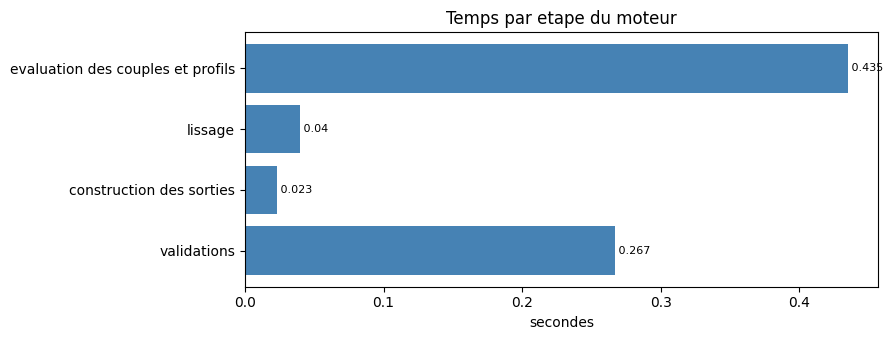

In [31]:
# Temps par etape.
perf = pd.DataFrame([{"etape": k, "temps (s)": round(v, 3)} for k, v in res["temps"].items()])
perf.loc[len(perf)] = {"etape": "TOTAL", "temps (s)": round(res["total"], 3)}
display(perf)
fig, ax = plt.subplots(figsize=(9, 3.5))
et = perf[perf.etape != "TOTAL"]
ax.barh(et["etape"], et["temps (s)"], color="steelblue"); ax.invert_yaxis()
ax.set_title("Temps par etape du moteur"); ax.set_xlabel("secondes")
for i, v in enumerate(et["temps (s)"]): ax.text(v, i, " " + str(v), va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Notre constat :** le moteur complet de la version choisie tourne très en dessous de
la limite de 90 secondes (**OK**). L'étape la plus coûteuse est l'évaluation des
couples et profils ; le lissage, la construction des sorties et les validations sont
quasi instantanés. Le budget de temps est tenu avec une large marge.

## Section Comparaison : les trois versions du moteur

Nous lançons `lancer_moteur` pour **chaque version** (évaluation, lissage, sorties,
validations), avec les mêmes réglages. Pour chacune, nous mesurons : le coût,
l'économie en € et en % par rapport à la baseline avec H20, les camions, les livraisons,
la part des livraisons du lundi, la **part des semaines respectées** (semaines
respectées / semaines du profil, tous couples) et le temps de calcul, qui doit rester
sous 90 secondes. Le tableau est enregistré dans `comparaison_versions.csv`.

In [32]:
# Les trois versions, chacune avec le moteur complet (evaluation, lissage, sorties, validations).
resultats_versions = {}; lignes_v = []
for mode in MODES:
    print(f"Version {mode} :")
    t0 = time.perf_counter()
    r = lancer_moteur({"UN_CAMION_PAR_JOUR": UN_CAMION_PAR_JOUR, "MODE_PROFIL": mode,
                       "TOLERANCE_LISSAGE": TOLERANCE_LISSAGE, "TEMPS_MAX_SECONDES": TEMPS_MAX_SECONDES},
                      afficher=False)
    duree = time.perf_counter() - t0
    resultats_versions[mode] = r
    cout_v, cam_v, liv_v = totaux(r["choix"])
    sem = semaines_par_couple(r["choix"], r["contenu"])
    resp = sum(a for a, n in sem.values()); nb_sem = sum(n for a, n in sem.values())
    lignes_v.append({"version": mode, "cout": round(cout_v, 2),
                     "economie EUR": round(baseline_H20 - cout_v, 2),
                     "economie %": round((baseline_H20 - cout_v) / baseline_H20 * 100, 1),
                     "camions": cam_v, "livraisons": liv_v, "part lundi %": round(part_lundi(r["choix"])[2], 1),
                     "semaines respectees": resp, "semaines du profil": nb_sem,
                     "part semaines respectees %": round(resp / nb_sem * 100, 1),
                     "temps (s)": round(duree, 2), "temps < 90 s": "OK" if duree <= TEMPS_MAX_SECONDES else "ECHEC"})
comparaison_versions = pd.DataFrame(lignes_v)
print()
display(comparaison_versions)
print("Toutes les versions sous", TEMPS_MAX_SECONDES, "s :",
      "OK" if (comparaison_versions["temps < 90 s"] == "OK").all() else "ECHEC")
print(f"Version retenue dans les sorties (MODE_PROFIL) : {MODE_PROFIL} | meme cout qu'en section 7 :",
      abs(resultats_versions[MODE_PROFIL]["cout"] - cout_final) < 0.01)
comparaison_versions.to_csv(DOSSIER + "comparaison_versions.csv", index=False)
print("Enregistre :", DOSSIER + "comparaison_versions.csv")

Version libre :


Toutes les validations passent (13 controles, version libre).
Version intermediaire :


Toutes les validations passent (13 controles, version intermediaire).
Version strict :


Toutes les validations passent (13 controles, version strict).



,version,cout,economie EUR,economie %,camions,livraisons,part lundi %,semaines respectees,semaines du profil,part semaines respectees %,temps (s),temps < 90 s
0,libre,74908.40,68412.34,47.7,567,566,20.1,572,1170,48.9,1.80,OK
1,intermediaire,79095.62,64225.12,44.8,618,617,23.2,867,1183,73.3,3.81,OK
2,strict,82110.82,61209.92,42.7,652,651,25.2,914,914,100.0,0.74,OK


Toutes les versions sous 90 s : OK
Version retenue dans les sorties (MODE_PROFIL) : strict | meme cout qu'en section 7 : True
Enregistre : ../data/processed/comparaison_versions.csv


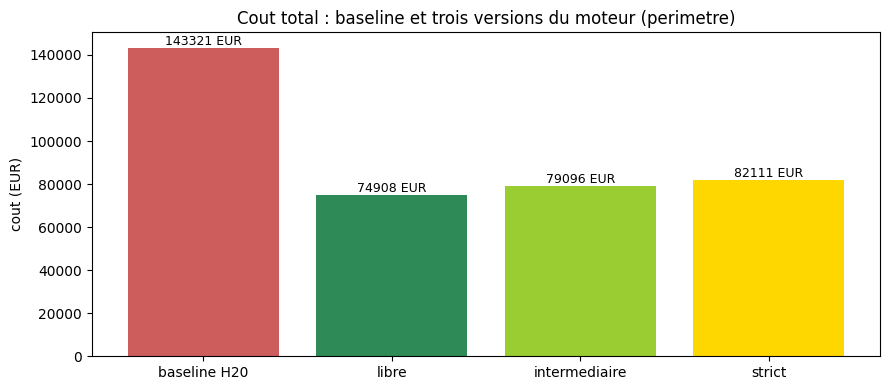

  libre         :   74908.40 EUR | +    0.00 EUR vs libre (+0.0 %) | semaines respectees 48.9 %
  intermediaire :   79095.62 EUR | + 4187.22 EUR vs libre (+5.6 %) | semaines respectees 73.3 %
  strict        :   82110.82 EUR | + 7202.42 EUR vs libre (+9.6 %) | semaines respectees 100.0 %


In [33]:
# Cout des trois versions, avec la baseline.
noms = ["baseline H20"] + list(comparaison_versions["version"])
valeurs = [baseline_H20] + list(comparaison_versions["cout"])
fig, ax = plt.subplots(figsize=(9, 4))
barres = ax.bar(noms, valeurs, color=["indianred", "seagreen", "yellowgreen", "gold"])
ax.set_title("Cout total : baseline et trois versions du moteur (perimetre)"); ax.set_ylabel("cout (EUR)")
for b, v in zip(barres, valeurs):
    ax.text(b.get_x() + b.get_width() / 2, v, str(round(v)) + " EUR", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

# Combien coute la regularite : ecart de chaque version par rapport a la version libre.
c_libre = comparaison_versions.set_index("version").loc["libre", "cout"]
for _, l in comparaison_versions.iterrows():
    print(f"  {l['version']:13s} : {l['cout']:10.2f} EUR | +{l['cout'] - c_libre:8.2f} EUR vs libre "
          f"(+{(l['cout'] - c_libre) / c_libre * 100:.1f} %) | semaines respectees {l['part semaines respectees %']} %")

**Notre constat :** les trois versions respectent toutes les règles (**13 contrôles**
chacune, dont la règle propre à la version) et tournent toutes **sous 90 secondes**
(**OK**). Toutes dépassent largement l'objectif de 35 % d'économie. Elles dessinent un
choix clair entre **économie** et **régularité** :

| version | coût | économie vs baseline H20 | livraisons | semaines respectées | surcoût vs libre |
|---|---|---|---|---|---|
| libre | 74 908 € | 68 412 € (47,7 %) | 566 | 48,9 % | — |
| intermédiaire | 79 096 € | 64 225 € (44,8 %) | 617 | 73,3 % | + 4 187 € (+5,6 %) |
| strict | 82 111 € | 61 210 € (42,7 %) | 651 | 100,0 % | + 7 202 € (+9,6 %) |

- **strict** (notre recommandation) donne un rythme **entièrement prévisible** (**100 %**
  des semaines respectées) : un profil proposé est un engagement, le fournisseur vient au
  rythme annoncé chaque semaine. Elle garde **42,7 %** d'économie.
- **libre** donne le **coût le plus bas**, mais le profil n'est qu'un maximum : moins
  d'une semaine sur deux est respectée (**48,9 %**). Une usine ne peut pas compter sur le
  rythme annoncé. Elle économise **7 202 €** de plus que la stricte.
- **intermédiaire** se place entre les deux : **73,3 %** des semaines respectées, et au
  moins 4 semaines par couple, pour **4 187 €** de plus que la libre.

Plus la version est régulière, plus la part des livraisons du lundi monte (**20,1 %**,
**23,2 %**, **25,2 %**). Nous recommandons la **version stricte** : la régularité du
rythme annoncé vaut largement les **7 202 €** d'écart avec la version libre. Le choix
final reste au client, par le paramètre `MODE_PROFIL`.

## Section 11 : Notre bilan

Notre moteur choisit, pour chaque couple fournisseur x usine, **un profil de livraison
stable**, décide **quels jours livrer** par programmation dynamique, regroupe les besoins
dans **un camion par jour** (H19), lisse la charge dans la semaine, puis chiffre
l'économie. Nous proposons **trois versions**, choisies avec le paramètre `MODE_PROFIL` :

| version | ce que fait le moteur | coût | économie vs baseline H20 | semaines respectées |
|---|---|---|---|---|
| strict (recommandée) | tous les jours du profil, chaque semaine | 82 111 € | 61 210 € (42,7 %) | 100,0 % |
| intermédiaire | au moins 4 semaines respectées par couple (toutes si moins de 4) | 79 096 € | 64 225 € (44,8 %) | 73,3 % |
| libre | le profil est un maximum : il retient les jours qu'il veut | 74 908 € | 68 412 € (47,7 %) | 48,9 % |

**Notre recommandation : la version stricte.** Un **profil proposé est un engagement**
envers le fournisseur : s'il annonce deux passages par semaine, il vient deux fois, et
apporte à chaque passage ce qu'il faut jusqu'à son prochain passage. La version stricte
tient ce rythme toutes les semaines et ne coupe jamais une ligne.

**Ce que le client gagne ou perd avec chacune :**

- **strict** (recommandée) : le rythme annoncé est tenu **toutes les semaines** ; il garde
  **42,7 %** d'économie (652 camions au lieu de 1 604) ; il paie **7 202 €** de plus que la
  version libre, c'est le prix de la régularité ;
- **intermédiaire** : il garde **44,8 %** d'économie et un rythme tenu sur 73,3 % des
  semaines ; il paie **4 187 €** de plus que la version libre ;
- **libre** : il gagne le plus (**47,7 %**, avec 567 camions au lieu de 1 604), mais il
  perd la régularité : le rythme annoncé n'est tenu que sur 48,9 % des semaines.

Les trois versions dépassent l'objectif des 35 %, passent **treize validations** et
tournent en **moins de 90 secondes**. Les sorties (`profils_couples.csv`,
`contenu_camions.csv`, `resume_economies.csv`) sont celles de la version choisie, ici
**stricte** ; le tableau des trois versions est dans `comparaison_versions.csv`.

La recherche du meilleur profil couple par couple est **exacte** grâce à R3. La
programmation dynamique est **exacte** en versions libre et intermédiaire (vérifiée par
force brute sur 30 cas) ; la version stricte n'a rien à choisir. Seuls les **3 couples aux
jours trop lourds** utilisent une **méthode approchée**.

**Nos hypothèses de ce milestone :**

- **H19 (un camion par couple et par jour)** : notre choix. Les livraisons sont plus
  simples et plus sûres (une ligne n'est jamais coupée) ; en version stricte, cela coûte
  un peu plus que le multi-camions (81 963 € contre 81 223 € à l'étape 1), largement
  justifié par un rythme tenu et des lignes jamais coupées.
- **H20 (envoi exceptionnel pour une ligne trop lourde)** : la seule ligne de plus de
  24 500 kg (SUP_00074 x PLT_003, le 15/12, 26 905,2 kg) part en un camion ">4000".
  Appliquée aussi à la situation actuelle, elle fixe une baseline à règles égales
  (143 321 €).
- **H21 (trois versions du profil)** : nous **recommandons la version stricte**, car un
  profil proposé est un engagement envers le fournisseur. Les versions libre et
  intermédiaire montrent ce que coûterait plus de souplesse ; le choix final reste au
  client. L'objectif de la version intermédiaire (`MIN_SEMAINES_RESPECTEES` = 4) est
  réglable.
- Rappel : **H17** (tolérance de lissage 2 %), **H18** (profils élargis), **H15/H16**
  (lignes inconnues inchangées, 35 032 €), **H7** (pas de livraison la semaine de Noël).

**Pourquoi le remplissage médian reste bas.** Un camion ne transporte qu'un seul
fournisseur (R3) : les petits fournisseurs restent dans de petits camions, ce qui tire la
médiane vers le bas. Le gain ne vient pas de camions pleins partout, mais du **nombre de
camions en moins** (1 604 -> 652 en version stricte).

**Nos limites :**

- les profils sont stables sur **7 semaines** : sur un horizon plus long, il faudrait
  vérifier qu'ils tiennent ;
- le lissage et le traitement des 3 couples aux jours trop lourds sont **approchés**
  (règles gloutonnes, puis suppression de livraisons tant que le coût baisse), là où la
  programmation dynamique est exacte pour les autres couples ;
- les **lignes inconnues** ne sont pas optimisées ; compléter leurs données ouvrirait une
  économie supplémentaire.